<a href="https://colab.research.google.com/github/twobombs/thereminq-examples/blob/main/devices/announced/nighthawk-r3/nighthawk_qrack_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Nighthawk Qrack (`nighthawk_qrack.py`): Google Colab Setup & Verification

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/twobombs/thereminq-examples/blob/main/devices/announced/nighthawk-r3/nighthawk_qrack_colab.ipynb)

This notebook sets up and verifies [`nighthawk_qrack.py`](https://github.com/twobombs/thereminq-examples/blob/main/devices/announced/nighthawk-r3/nighthawk_qrack.py), the consolidated clean-qubit **PyQrack** companion to `arXiv:2609.28657` (random-circuit sampling on IBM Nighthawk r2 / `ibm_phoenix`, 61 qubits) and IBM Nighthawk r3 / multi-chip cloverfield simulations.

### Workflow
1. **Install dependencies** (pinned `pyqrack`, `qiskit`, `ortools`, `scipy`, `matplotlib`, `numpy`; the Qrack runtime libraries `libclblast1`, `libopenblas0`, `ocl-icd-libopencl1`; and OpenCL via NVIDIA ICD on GPU runtimes or `pocl-opencl-icd` on CPU runtimes).
2. **Clone repositories** (`twobombs/thereminq-examples` and `BlueQubitDev/rcs-nighthawk`).
3. **Verify circuits & release data** (`verify` and `seamgap`).
4. **Run the self-test suites** (`selftest`, `ghz selftest`, `field selftest`, `erepr selftest`, `lab --selftest`).
5. **Dimension ACE patches from available system RAM / OpenCL stack memory** and run Nighthawk r2/r3 & Cloverfield plans and quick simulations (`aceplan`, `field plan`, `run`, `field run`).

## 1. Environment & Dependency Setup

Run the cell below to install Python packages (`pyqrack` pinned to `PYQRACK_VERSION`, `qiskit`, `ortools`, `scipy`, `matplotlib`) and the shared libraries the PyQrack wheel links against (`libclblast1`, `libopenblas0`, `ocl-icd-libopencl1`), then configure OpenCL (NVIDIA OpenCL ICD when a GPU is detected, or `pocl-opencl-icd` when running on CPU).

Before importing PyQrack the cell runs `ldd` on `libqrack_pinvoke.so` and stops with the names of any missing libraries. PyQrack's own import error only reports its last fallback path (`/usr/lib/qrack/libqrack_pinvoke.so`), which hides the real cause.

| Setting | Default | Meaning |
|---|---|---|
| `PYQRACK_VERSION` | `2.30.6` | PyQrack release the self-tests in this notebook last passed on; bump after a clean run |
| `QRACK_LIB_PATH` | `/usr/local/lib/qrack/libqrack_pinvoke.so` | used instead of the wheel's library when present (same convention as `nighthawk_qrack.py`) |

In [1]:
import importlib.util
import os
import shutil
import subprocess
import sys
from pathlib import Path

PYQRACK_VERSION = "2.30.6"   # last release this notebook's self-tests passed on; bump after a clean run

# Same convention as nighthawk_qrack.py: a locally built Qrack takes precedence over the wheel's library
QRACK_LIB_PATH = "/usr/local/lib/qrack/libqrack_pinvoke.so"
if os.path.exists(QRACK_LIB_PATH):
    os.environ["PYQRACK_SHARED_LIB_PATH"] = QRACK_LIB_PATH

# Install required Python packages
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    f"pyqrack=={PYQRACK_VERSION}", "qiskit", "ortools", "scipy", "matplotlib", "numpy"
])

# Shared libraries the PyQrack wheel's libqrack_pinvoke.so links against, needed on GPU and CPU runtimes alike
QRACK_RUNTIME_PKGS = ["ocl-icd-libopencl1", "libclblast1", "libopenblas0", "clinfo"]

# Check for GPU via nvidia-smi; if no GPU is detected, install PoCL (pocl-opencl-icd)
has_nvidia = shutil.which("nvidia-smi") is not None and subprocess.call(
    ["nvidia-smi"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL
) == 0

subprocess.check_call(["apt-get", "update", "-qq"])
if has_nvidia:
    print("GPU detected via nvidia-smi; configuring NVIDIA OpenCL ICD...")
    subprocess.check_call(["apt-get", "install", "-y", "-qq", *QRACK_RUNTIME_PKGS])
    os.makedirs("/etc/OpenCL/vendors", exist_ok=True)
    nv_icd = "/etc/OpenCL/vendors/nvidia.icd"
    if not os.path.exists(nv_icd):
        # Full path when the driver library is found (Colab keeps it in /usr/lib64-nvidia), else the soname
        nv_lib = next((str(p) for d in ("/usr/lib64-nvidia", "/usr/lib/x86_64-linux-gnu", "/usr/lib64")
                       for p in [Path(d) / "libnvidia-opencl.so.1"] if p.exists()), "libnvidia-opencl.so.1")
        with open(nv_icd, "w") as f:
            f.write(nv_lib + "\n")
else:
    print("No GPU detected; installing PoCL (pocl-opencl-icd) for CPU OpenCL support...")
    subprocess.check_call(["apt-get", "install", "-y", "-qq", "pocl-opencl-icd", *QRACK_RUNTIME_PKGS])

print("\nOpenCL devices (clinfo -l):")
clinfo_out = subprocess.run(["clinfo", "-l"], capture_output=True, text=True).stdout
print(clinfo_out)
if has_nvidia and "nvidia" not in clinfo_out.lower():
    print("WARNING: nvidia-smi sees a GPU but OpenCL lists no NVIDIA platform; check /etc/OpenCL/vendors/nvidia.icd")

# Resolve libqrack_pinvoke.so's dependencies before importing PyQrack, so a missing library is named
_spec = importlib.util.find_spec("pyqrack")
_wheel_lib = Path(_spec.submodule_search_locations[0]) / "qrack_system" / "qrack_lib" / "libqrack_pinvoke.so"
qrack_lib = Path(QRACK_LIB_PATH) if os.path.exists(QRACK_LIB_PATH) else _wheel_lib
ldd_out = subprocess.run(["ldd", str(qrack_lib)], capture_output=True, text=True).stdout
missing = sorted({line.split("=>")[0].strip() for line in ldd_out.splitlines() if "not found" in line})
if missing:
    raise RuntimeError(f"{qrack_lib} cannot load; missing shared libraries: {', '.join(missing)}. "
                       f"Install the packages that provide them (apt-get install {' '.join(QRACK_RUNTIME_PKGS)}).")
print(f"Qrack library: {qrack_lib} (all dependencies resolved)")

import pyqrack
from importlib.metadata import version
print(f"\nPyQrack version: {version('pyqrack')}")
print(f"Qiskit version:  {version('qiskit')}")
print(f"OR-Tools version: {version('ortools')}")

GPU detected via nvidia-smi; configuring NVIDIA OpenCL ICD...

OpenCL devices (clinfo -l):
Platform #0: NVIDIA CUDA
 `-- Device #0: NVIDIA L4

Qrack library: /usr/local/lib/python3.13/dist-packages/pyqrack/qrack_system/qrack_lib/libqrack_pinvoke.so (all dependencies resolved)

PyQrack version: 2.30.6
Qiskit version:  2.6.2
OR-Tools version: 9.15.6755


## 2. Clone Repositories & Set Working Directory

This cell clones `twobombs/thereminq-examples` (if not already present), moves into `devices/announced/nighthawk-r3`, and clones the `BlueQubitDev/rcs-nighthawk` dataset next to `nighthawk_qrack.py`.

In [2]:
import os
import re
import shlex
import subprocess
import threading
import time
from pathlib import Path

if not Path("nighthawk_qrack.py").is_file():
    if not Path("thereminq-examples").is_dir():
        !git clone --depth 1 https://github.com/twobombs/thereminq-examples.git
    %cd thereminq-examples/devices/announced/nighthawk-r3

if not Path("rcs-nighthawk/data/layout.json").is_file():
    !git clone --depth 1 https://github.com/BlueQubitDev/rcs-nighthawk.git rcs-nighthawk

os.environ["NIGHTHAWK_REPO"] = str(Path("rcs-nighthawk").resolve())
print("Working directory:", Path.cwd())
print("NIGHTHAWK_REPO:   ", os.environ["NIGHTHAWK_REPO"])

# Qrack prints this once per process that starts with OpenCL hidden (CPU chip workers, the loom); see run_logged
_HIDDEN_OCL_LINE = "No platforms found. Check OpenCL installation!"


def run_logged(cmd, cwd=None, timeout=None, echo=True, quiet=False, on_line=None):
    """Run a command and stream its output into the notebook, so it is saved with the cell.
    (A plain subprocess.run writes to the kernel's file descriptors, which Colab does not keep.)
    Collapses Qrack's per-process 'No platforms found' line from OpenCL-hidden workers into one count.
    on_line(line) is called for every output line (e.g. to follow which depth a run is on).
    Returns dict(rc, out, seconds, timed_out); raises CalledProcessError on a non-zero exit."""
    if echo:
        print(f"$ {shlex.join(cmd)}", flush=True)
    t0 = time.time()
    p = subprocess.Popen(cmd, cwd=cwd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
                         start_new_session=True)
    lines, hidden, expired = [], 0, []

    def _expire():
        expired.append(True)
        try:
            os.killpg(p.pid, 9)        # the run's chip workers and loom too, not only the launcher
        except OSError:
            pass

    timer = threading.Timer(timeout, _expire) if timeout else None
    if timer:
        timer.start()
    try:
        for line in p.stdout:
            if line.strip() == _HIDDEN_OCL_LINE:
                hidden += 1
                continue
            lines.append(line)
            if on_line is not None:
                on_line(line)
            if not quiet:
                print(line, end="", flush=True)
        p.wait()
    except KeyboardInterrupt:
        _expire()
        raise
    finally:
        if timer:
            timer.cancel()
    timed_out = bool(expired)
    secs = time.time() - t0
    if timed_out:
        print(f"TIMEOUT after {timeout:g} s: stopped")
    if hidden and not quiet:
        print(f"({hidden} x '{_HIDDEN_OCL_LINE}' from OpenCL-hidden worker processes, expected)")
    out = "".join(lines)
    if p.returncode and not timed_out:
        if quiet:
            print(out[-4000:])
        raise subprocess.CalledProcessError(p.returncode, cmd, out)
    return dict(rc=p.returncode, out=out, seconds=secs, timed_out=timed_out)


def failed_points(out: str) -> str:
    """'' when a run finished all its points, else the run's own failure line (a chip worker that exits is
    retried once; points that fail twice go to <out>.failed.json and the run still exits 0)."""
    m = re.search(r"^# (\d+ point\(s\) (?:failed twice|marked failed).*)$", out, re.M)
    return m.group(1) if m else ""


Cloning into 'thereminq-examples'...
remote: Enumerating objects: 832, done.
remote: Counting objects: 100% (832/832), done.
remote: Compressing objects: 100% (689/689), done.
remote: Total 832 (delta 146), reused 698 (delta 130), pack-reused 0 (from 0)
Receiving objects: 100% (832/832), 186.25 MiB | 19.96 MiB/s, done.
Resolving deltas: 100% (146/146), done.
/content/thereminq-examples/devices/announced/nighthawk-r3
Cloning into 'rcs-nighthawk'...
remote: Enumerating objects: 588, done.
remote: Counting objects: 100% (588/588), done.
remote: Compressing objects: 100% (144/144), done.
remote: Total 588 (delta 442), reused 579 (delta 442), pack-reused 0 (from 0)
Receiving objects: 100% (588/588), 39.31 MiB | 20.17 MiB/s, done.
Resolving deltas: 100% (442/442), done.
Working directory: /content/thereminq-examples/devices/announced/nighthawk-r3
NIGHTHAWK_REPO:    /content/thereminq-examples/devices/announced/nighthawk-r3/rcs-nighthawk


## 3. Circuit & Release Data Verification (`verify` & `seamgap`)

- `verify` regenerates all 233 circuits from `data/layout.json` and checks them gate-for-gate against `data/circuits/*.qasm`.
- `seamgap` runs the data-only analysis of CZ counts and fidelity vs. depth fits on the released dataset.

In [3]:
!python3 nighthawk_qrack.py verify --repo rcs-nighthawk
!python3 nighthawk_qrack.py seamgap --repo rcs-nighthawk

232 identical, 0 different (angle tol 1e-09 rad)
== CZ counts (mean [min-max]); gaps relative to the sampled full circuit ==
depth	full	mirror	K3	K4	full-mirror	full-K3
4	102[102-102]	94[94-94]	-	-	8 (7.8%)	-
6	-	150[150-150]	-	-	-	-
8	204[204-204]	190[190-190]	-	-	14 (6.9%)	-
10	-	232[232-232]	-	-	-	-
12	306[306-306]	264[264-264]	-	-	42 (13.7%)	-
14	-	312[312-312]	-	-	-	-
16	408[408-408]	348[348-348]	-	-	60 (14.7%)	-
18	-	398[398-398]	-	-	-	-
20	510[510-510]	442[442-442]	444[440-450]	401[395-415]	68 (13.3%)	66 (12.9%)
24	612[612-612]	532[532-532]	533[528-540]	481[474-498]	80 (13.1%)	79 (12.9%)
28	714[714-714]	616[616-616]	622[616-630]	561[553-581]	98 (13.7%)	92 (12.9%)
32	816[816-816]	706[706-706]	710[704-720]	642[632-664]	110 (13.5%)	106 (12.9%)
36	918[918-918]	802[802-802]	799[792-810]	722[711-747]	116 (12.6%)	119 (12.9%)
40	1020[1020-1020]	888[888-888]	888[880-900]	802[790-830]	132 (12.9%)	132 (12.9%)

== fit F(d) = 0.3257 x 0.8717^d ==
at d=36: 2.321e-03 (headline);  at gate-count

## 4. Self-Test Suites

Run the built-in self-tests across all command groups to confirm exactness, angle conventions, Pauli twirling, XEB scoring, CP-SAT layout search, VQE, Shor-9, QrackBridge, GHZ, Cloverfield loom, ER=EPR, and the Configuration Lab.

In [4]:
# Main self-test suite (14 checks: circuit regeneration, Haar u_angles, exact mirror, Pauli twirl,
# ideal patch XEB, hardware counts XEB, ACE mapping, register recipe, CP-SAT layoutsearch,
# nnqab gate inverses, TFIM VQE, Shor-9, and horizontal QrackBridge)
!python3 nighthawk_qrack.py selftest --repo rcs-nighthawk

[1] angle hash + pseudo-patch rotation vs released mirror/d08_instance1.qasm: identical  OK
Device #0, Building JIT.
Default platform: NVIDIA CUDA
Default device: #0, NVIDIA L4
OpenCL device #0: NVIDIA L4
[2] u_angles -> Qrack u == Haar matrix: overlap 1.0000001  OK
# progress n14 mirror d12 i0: circuit run 1/10, 10.0% of cycles, elapsed 0m00s, ETA 0m00s
[3] exact mirror, first 14 logical qubits, d=12, 10 inputs: F = 0.9999999  OK
[4] Pauli-frame twirl is an identity (exact): F = 1.0000000  OK
[5] PyQrack patch ideal XEB vs release (Aer, double): max diff 2.0e-08  OK
[6] Eq.(1)-(2) on the hardware counts vs release: 0.02555 vs 0.02555 (se 3.9e-03)  OK
[7] ideal samples score F = 1 within 4 se: F = 0.9531 +/- 0.0378  OK
[8] ACE register 64 qubits, grid 8x8, is_torus=False; logical->ACE map is nearest-neighbour for all couplers: True
[9] --register recipe reproduces the release's inputs and K = 3, 4 partitions: identical  OK
[10] layoutsearch joint model vs exact engine, release register

In [5]:
# Subgroup self-tests: ghz, field, erepr, and lab
!python3 nighthawk_qrack.py ghz selftest
!python3 nighthawk_qrack.py field selftest
!python3 nighthawk_qrack.py erepr selftest
!python3 nighthawk_qrack.py lab --selftest

[1] Lemma 4 (MQC) and the witness against numpy density matrices (k = 3, 4, 5)
  [ok] k=3 theta=0.0 flip=0.0 dephase=0.0: c +0.5000+0.0000i / +0.5000+0.0000i, F_GHZ 1.0000 / max_theta 1.0000, F0 1.0000 / 1.0000, witness 1.0000
  [ok] k=3 theta=0.7 flip=0.0 dephase=0.0: c +0.3824-0.3221i / +0.3824-0.3221i, F_GHZ 1.0000 / max_theta 1.0000, F0 0.8824 / 0.8824, witness 0.8824
  [ok] k=3 theta=0.0 flip=0.1 dephase=0.0: c +0.4500+0.0000i / +0.4500+0.0000i, F_GHZ 0.9000 / max_theta 0.9000, F0 0.9000 / 0.9000, witness 0.9000
  [ok] k=3 theta=0.3 flip=0.05 dephase=0.4: c +0.2723-0.0842i / +0.2723-0.0842i, F_GHZ 0.7600 / max_theta 0.7600, F0 0.7473 / 0.7473, witness 0.7366
  [ok] k=4 theta=0.0 flip=0.0 dephase=0.0: c +0.5000+0.0000i / +0.5000+0.0000i, F_GHZ 1.0000 / max_theta 1.0000, F0 1.0000 / 1.0000, witness 1.0000
  [ok] k=4 theta=0.7 flip=0.0 dephase=0.0: c +0.3824-0.3221i / +0.3824-0.3221i, F_GHZ 1.0000 / max_theta 1.0000, F0 0.8824 / 0.8824, witness 0.8824
  [ok] k=4 theta=0.0 flip=0.1 de

## 5. Adaptive Patch Dimensioning (System RAM / OpenCL Stack), Device Plans & Quick Run

Probe the host's available **system RAM** (`/proc/meminfo` + Linux cgroup limits) and **OpenCL stack** (`CL_DEVICE_GLOBAL_MEM_SIZE`, `CL_DEVICE_MAX_MEM_ALLOC_SIZE`, PCI address, and live free VRAM via `nvidia-smi` on NVIDIA or `mem_info_vram_*` sysfs on amdgpu) alongside PyQrack's amplitude precision (`Qrack.fppow`). Every GPU is used; a die listed under two OpenCL platforms (e.g. ROCm and clvk) counts once. No card size is assumed: an L4, an A100, 6x 8 GB V340 dies or a CPU-only runtime are all sized from what the probe reports.

| Workload | How it is sized |
|---|---|
| 61-qubit Nighthawk r2 ACE (`--ace-max-width`) | Qrack's OpenCL VRAM rule (3x state size within VRAM, single buffer within `CL_DEVICE_MAX_MEM_ALLOC_SIZE`) or host RAM (within 80 % of available, compose transient included) |
| Cloverfield `r3x2s` (2 chips), `r3t` (4 tiles), `clover6` (6 chiplets), `r3x2t` (IBM's two-chip r3x2 as 8 tiles, 1,040 qubits) | the run's own arguments are handed to `nighthawk_qrack.py field plan`, which places chips on devices as the run does (`--gpus`, `--chips-per-gpu`) and sums the chips sharing each device; the widest `--ghost-max-width` that fits is found by bisection; the `GHOST_SCAN_BELOW` caps under it are planned too and the one with the most links is used (a wider cap can place fewer links where a die holds one chip); the next cap up is then tried with 1, 2, ... patches per chip at it (`--ghost-max-wide`) while that fits and adds links; else the mean-field loom, else the device is skipped |

Every plan carries the runs' `--no-ace-error-detection`, so the planner counts each patch as the simulator the runs allocate (no ancilla qubit: half the memory a patch with error detection takes; README 3.16).

Each plan also draws its field map (`--png`): the ACE patches of every chip (tint and outline, patch numbers), seam qubits, link anchors, the links the loom placed and the couplers between chips left without one, and per chip its patch count, widest patch and peak GiB.

Plan and run use identical arguments, so the verdict printed for a device is about the run that follows. All command output is streamed into the notebook (`run_logged`, defined in section 2) so it is saved with the cells.


In [6]:
import json
import math
import os
import re
import shutil
import subprocess
import sys
from pathlib import Path

# Optional manual overrides (leave as None / False for automatic detection)
OVERRIDE_VRAM_GIB = None   # e.g. 15.0 for T4, 40.0 for A100
OVERRIDE_RAM_GIB = None    # e.g. 12.7 for standard Colab CPU, 51.0 for High-RAM
PREFER_CPU = False         # set True to ignore OpenCL GPUs and dimension for system RAM
# Cloverfield plans are checked against PLAN_SCALE x the detected budget (VRAM per device, or host RAM).
# The planner counts every patch dense plus one compose buffer per chip at once, each patch as the simulator
# the runs allocate (they pass --no-ace-error-detection: no ancilla qubit per patch). 1.0 keeps that worst
# case; above 1.0 allows wider ghost caps and tiles, at the risk of running out of memory when the compose
# buffers of several chips do coincide. The max single allocation (widest patch) is never scaled.
PLAN_SCALE = 1.0
# The benchmark runs use no error-detection ancilla (nnqab, --no-ace-error-detection), so every ACE patch is
# one qubit narrower than its cap counted with the ancilla: half the memory. Plans pass the same flag.
RUN_ARGS_ED = ["--no-ace-error-detection"]
ED_ANCILLA = 0             # qubits the runs' ACE adds per patch (1 with error detection)

GIB = 2 ** 30
GTT_RESERVE_GB = 0.5       # matches nighthawk_qrack.GTT_RESERVE_GB (driver/kernels/buffers)
HOST_RESERVE_FRAC = 0.80   # keep >=20% host RAM headroom
HOST_OVERHEAD_GIB = 1.0    # matches nighthawk_qrack.host_plan (Python/OS/Qrack runtime)


def patch_gib(width: int, amp_bytes: int = 8) -> float:
    return (2.0 ** int(width)) * amp_bytes / GIB


def max_width_for_bytes(max_bytes: float, amp_bytes: int = 8) -> int:
    if max_bytes <= amp_bytes:
        return 1
    return int(math.floor(math.log2(max_bytes / amp_bytes)))


def probe_system_ram() -> dict:
    """Detect total/available host RAM (GiB), honoring Linux cgroup v2/v1 container limits."""
    mem_total_kb = None
    mem_avail_kb = None
    swap_free_kb = 0
    try:
        with open("/proc/meminfo") as f:
            for line in f:
                if line.startswith("MemTotal:"):
                    mem_total_kb = int(line.split()[1])
                elif line.startswith("MemAvailable:"):
                    mem_avail_kb = int(line.split()[1])
                elif line.startswith("SwapFree:"):
                    swap_free_kb = int(line.split()[1])
    except OSError:
        pass

    if mem_total_kb is None:
        try:
            mem_total_kb = (os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES")) // 1024
        except (ValueError, OSError, AttributeError):
            mem_total_kb = 8 * 1024 * 1024
    if mem_avail_kb is None:
        mem_avail_kb = int(mem_total_kb * 0.85)

    total_gib = mem_total_kb / (1024 * 1024)
    avail_gib = mem_avail_kb / (1024 * 1024)
    swap_free_gib = swap_free_kb / (1024 * 1024)

    cgroup_limit_gib = None
    cgroup_used_gib = None
    # cgroup v2
    cg2_max = Path("/sys/fs/cgroup/memory.max")
    cg2_cur = Path("/sys/fs/cgroup/memory.current")
    if cg2_max.is_file():
        try:
            raw = cg2_max.read_text().strip()
            if raw.isdigit():
                lim = int(raw)
                if 0 < lim < (1 << 60):
                    cgroup_limit_gib = lim / GIB
                    if cg2_cur.is_file():
                        cgroup_used_gib = int(cg2_cur.read_text().strip()) / GIB
        except (OSError, ValueError):
            pass
    # cgroup v1 fallback
    if cgroup_limit_gib is None:
        cg1_max = Path("/sys/fs/cgroup/memory/memory.limit_in_bytes")
        cg1_cur = Path("/sys/fs/cgroup/memory/memory.usage_in_bytes")
        if cg1_max.is_file():
            try:
                lim = int(cg1_max.read_text().strip())
                if 0 < lim < (1 << 60):
                    cgroup_limit_gib = lim / GIB
                    if cg1_cur.is_file():
                        cgroup_used_gib = int(cg1_cur.read_text().strip()) / GIB
            except (OSError, ValueError):
                pass

    if cgroup_limit_gib is not None and cgroup_limit_gib < total_gib:
        total_gib = cgroup_limit_gib
        if cgroup_used_gib is not None:
            avail_gib = min(avail_gib, max(0.25, cgroup_limit_gib - cgroup_used_gib))
        else:
            avail_gib = min(avail_gib, cgroup_limit_gib * 0.85)

    return dict(
        total_gib=round(total_gib, 2),
        avail_gib=round(avail_gib, 2),
        swap_free_gib=round(swap_free_gib, 2),
        cgroup_limit_gib=round(cgroup_limit_gib, 2) if cgroup_limit_gib is not None else None,
    )


# Subprocess OpenCL probe (avoids loading/pinning an OpenCL context in the notebook kernel)
_OCL_MEM_PROBE = r"""
import ctypes, json, sys
cl = None
for libname in (
    "libOpenCL.so.1",
    "libOpenCL.so",
    "/System/Library/Frameworks/OpenCL.framework/OpenCL",
):
    try:
        cl = ctypes.CDLL(libname)
        break
    except OSError:
        continue
if cl is None:
    print("[]")
    sys.exit(0)

vp, u32, u64, sz = ctypes.c_void_p, ctypes.c_uint32, ctypes.c_uint64, ctypes.c_size_t
cl.clGetPlatformIDs.argtypes = [u32, ctypes.POINTER(vp), ctypes.POINTER(u32)]
cl.clGetPlatformInfo.argtypes = [vp, u32, sz, vp, ctypes.POINTER(sz)]
cl.clGetDeviceIDs.argtypes = [vp, u64, u32, ctypes.POINTER(vp), ctypes.POINTER(u32)]
cl.clGetDeviceInfo.argtypes = [vp, u32, sz, vp, ctypes.POINTER(sz)]

def info_str(fn, obj, param):
    n = sz()
    if fn(obj, param, 0, None, ctypes.byref(n)) or not n.value:
        return ""
    b = ctypes.create_string_buffer(n.value)
    fn(obj, param, n, b, None)
    return b.value.decode(errors="replace").strip()

def info_u64(d, param):
    v = u64()
    return int(v.value) if cl.clGetDeviceInfo(d, param, ctypes.sizeof(v), ctypes.byref(v), None) == 0 else 0

def info_u32(d, param):
    v = u32()
    return int(v.value) if cl.clGetDeviceInfo(d, param, ctypes.sizeof(v), ctypes.byref(v), None) == 0 else 0

# [domain, bus, device, function] of a GPU, or None: cl_khr_pci_bus_info (as nighthawk_qrack's own
# probe), else AMD's CL_DEVICE_TOPOLOGY_AMD, else NVIDIA's CL_DEVICE_PCI_*_NV queries
def pci_address(d):
    bus = (u32 * 4)()
    if cl.clGetDeviceInfo(d, 0x410F, ctypes.sizeof(bus), bus, None) == 0:      # CL_DEVICE_PCI_BUS_INFO_KHR
        return list(bus)
    topo = (ctypes.c_uint8 * 24)()
    if cl.clGetDeviceInfo(d, 0x4037, ctypes.sizeof(topo), topo, None) == 0:    # CL_DEVICE_TOPOLOGY_AMD
        if int.from_bytes(bytes(topo[0:4]), "little") == 1:                    # CL_DEVICE_TOPOLOGY_TYPE_PCIE_AMD
            return [0, topo[21], topo[22], topo[23]]
    nv_bus, nv_slot, nv_dom = info_u32(d, 0x4008), info_u32(d, 0x4009), info_u32(d, 0x400A)
    if nv_bus or nv_slot:
        return [nv_dom, nv_bus, nv_slot >> 3, nv_slot & 7]
    return None

np_ = u32()
if cl.clGetPlatformIDs(0, None, ctypes.byref(np_)) or not np_.value:
    print("[]")
    sys.exit(0)
plats = (vp * np_.value)()
cl.clGetPlatformIDs(np_.value, plats, None)

out = []
gidx = 0
for p in plats:
    pname = info_str(cl.clGetPlatformInfo, p, 0x0902)          # CL_PLATFORM_NAME
    nd = u32()
    if cl.clGetDeviceIDs(p, 0xFFFFFFFF, 0, None, ctypes.byref(nd)) or not nd.value:
        continue
    devs = (vp * nd.value)()
    cl.clGetDeviceIDs(p, 0xFFFFFFFF, nd.value, devs, None)
    for d in devs:
        dtype_bits = info_u64(d, 0x1000)                       # CL_DEVICE_TYPE
        if dtype_bits & 4:
            dtype = "GPU"
        elif dtype_bits & 8:
            dtype = "ACCELERATOR"
        elif dtype_bits & 2:
            dtype = "CPU"
        else:
            dtype = f"OTHER({dtype_bits})"
        out.append(dict(
            index=gidx,
            platform=pname,
            device=info_str(cl.clGetDeviceInfo, d, 0x102B),    # CL_DEVICE_NAME
            type=dtype,
            global_mem_bytes=info_u64(d, 0x101F),              # CL_DEVICE_GLOBAL_MEM_SIZE
            max_alloc_bytes=info_u64(d, 0x1010),               # CL_DEVICE_MAX_MEM_ALLOC_SIZE
            compute_units=info_u32(d, 0x1002),                 # CL_DEVICE_MAX_COMPUTE_UNITS
            pci=pci_address(d),
        ))
        gidx += 1
print(json.dumps(out))
"""


def _parse_clinfo_fallback() -> list:
    if not shutil.which("clinfo"):
        return []
    try:
        res = subprocess.run(["clinfo"], capture_output=True, text=True, timeout=30)
        text = res.stdout
    except (subprocess.SubprocessError, OSError):
        return []
    devs, cur, plat = [], None, ""
    for line in text.splitlines():
        m = re.match(r"\s*Platform Name\s+(.*)", line)
        if m:
            plat = m.group(1).strip()
            continue
        m = re.match(r"\s*Device Name\s+(.*)", line)
        if m:
            if cur is not None:
                devs.append(cur)
            cur = dict(index=len(devs), platform=plat, device=m.group(1).strip(),
                       type="UNKNOWN", global_mem_bytes=0, max_alloc_bytes=0, compute_units=0)
            continue
        if cur is None:
            continue
        m = re.match(r"\s*Device Type\s+(.*)", line)
        if m:
            t = m.group(1).upper()
            cur["type"] = "GPU" if "GPU" in t else ("ACCELERATOR" if "ACCEL" in t else ("CPU" if "CPU" in t else t.strip()))
        m = re.match(r"\s*Global memory size\s+(\d+)", line)
        if m:
            cur["global_mem_bytes"] = int(m.group(1))
        m = re.match(r"\s*Max memory allocation\s+(\d+)", line)
        if m:
            cur["max_alloc_bytes"] = int(m.group(1))
        m = re.match(r"\s*Max compute units\s+(\d+)", line)
        if m:
            cur["compute_units"] = int(m.group(1))
    if cur is not None:
        devs.append(cur)
    return devs


def pci_key(pci):
    """Canonical 'dddd:bb:dd.f' for a [domain, bus, device, function] list."""
    return "{:04x}:{:02x}:{:02x}.{:x}".format(*pci) if pci else None


def _pci_key_from_str(s: str):
    """nvidia-smi's '00000000:01:00.0' (or sysfs 'dddd:bb:dd.f') as pci_key."""
    m = re.match(r"\s*([0-9a-fA-F]+):([0-9a-fA-F]+):([0-9a-fA-F]+)\.([0-9a-fA-F])", s)
    return pci_key([int(x, 16) for x in m.groups()]) if m else None


def probe_nvidia_gpus() -> list:
    """Per NVIDIA GPU: pci, total / used / free GiB (nvidia-smi), or [] without it."""
    if not shutil.which("nvidia-smi"):
        return []
    try:
        res = subprocess.run(
            ["nvidia-smi", "--query-gpu=pci.bus_id,name,memory.total,memory.used,memory.free",
             "--format=csv,noheader,nounits"],
            capture_output=True, text=True, timeout=15,
        )
        if res.returncode != 0:
            return []
        gpus = []
        for line in res.stdout.strip().splitlines():
            parts = [p.strip() for p in line.split(",")]
            if len(parts) >= 5:
                gpus.append(dict(
                    pci=_pci_key_from_str(parts[0]),
                    name=parts[1],
                    total_gib=round(float(parts[2]) / 1024.0, 2),
                    used_gib=round(float(parts[3]) / 1024.0, 2),
                    free_gib=round(float(parts[4]) / 1024.0, 2),
                ))
        return gpus
    except (subprocess.SubprocessError, ValueError, OSError):
        return []


def amd_vram_gib(pci: str):
    """(total, used) GiB of an amdgpu die from sysfs, or None (no amdgpu driver / no such device)."""
    if not pci:
        return None
    base = Path("/sys/bus/pci/devices") / pci
    try:
        total = int((base / "mem_info_vram_total").read_text())
        used = int((base / "mem_info_vram_used").read_text())
        return total / GIB, used / GIB
    except (OSError, ValueError):
        return None


def probe_opencl_stack() -> list:
    devs = []
    try:
        res = subprocess.run([sys.executable, "-c", _OCL_MEM_PROBE], capture_output=True, text=True, timeout=30)
        if res.returncode == 0 and res.stdout.strip():
            devs = json.loads(res.stdout.strip().splitlines()[-1])
    except (subprocess.SubprocessError, ValueError, OSError):
        devs = []
    if not devs:
        devs = _parse_clinfo_fallback()

    nv_gpus = probe_nvidia_gpus()
    nv_by_pci = {g["pci"]: g for g in nv_gpus if g["pci"]}
    nv_i = 0
    seen_pci = {}
    for d in devs:
        d["global_mem_gib"] = round(d["global_mem_bytes"] / GIB, 2)
        d["max_alloc_gib"] = round(d["max_alloc_bytes"] / GIB, 2)
        d["pci"] = pci_key(d.get("pci"))
        d["free_mem_gib"] = None
        d["duplicate_of"] = None
        if d["type"] not in ("GPU", "ACCELERATOR"):
            continue
        # The same die under two platforms (e.g. ROCm and clvk on AMD): keep the first, global index order
        if d["pci"] and d["pci"] in seen_pci:
            d["duplicate_of"] = seen_pci[d["pci"]]
            continue
        if d["pci"]:
            seen_pci[d["pci"]] = d["index"]
        is_nv = "nvidia" in (d["platform"] + " " + d["device"]).lower()
        nv = nv_by_pci.get(d["pci"]) if d["pci"] else None
        if nv is None and is_nv and not d["pci"] and nv_i < len(nv_gpus):
            nv = nv_gpus[nv_i]                       # no PCI address from OpenCL: nvidia-smi order
        if is_nv and not d["pci"]:
            nv_i += 1
        if nv is not None:
            d["free_mem_gib"] = nv["free_gib"]
            d["pci"] = d["pci"] or nv["pci"]         # lets device_mem_used_gib find it again
            continue
        amd = amd_vram_gib(d["pci"])
        if amd is not None:
            d["free_mem_gib"] = round(amd[0] - amd[1], 2)
    return devs


def device_mem_used_gib(devs: list) -> dict:
    """Live used memory per OpenCL GPU index (NVIDIA via nvidia-smi, AMD via sysfs) plus 'host'
    (MemTotal - MemAvailable). Devices with no readable counter are left out."""
    out = {}
    nv = {g["pci"]: g for g in probe_nvidia_gpus() if g["pci"]}
    for d in devs:
        if d["type"] not in ("GPU", "ACCELERATOR") or d.get("duplicate_of") is not None:
            continue
        if d["pci"] in nv:
            out[d["index"]] = nv[d["pci"]]["used_gib"]
        else:
            amd = amd_vram_gib(d["pci"])
            if amd is not None:
                out[d["index"]] = amd[1]
    try:
        mi = {l.split(":")[0]: int(l.split()[1]) for l in open("/proc/meminfo") if l.split()[1:2]}
        out["host"] = (mi["MemTotal"] - mi["MemAvailable"]) / (1024 * 1024)
    except (OSError, KeyError, ValueError):
        pass
    return out


def probe_amp_bytes() -> int:
    try:
        from pyqrack.qrack_system import Qrack
        return 2 ** (int(Qrack.fppow) - 2)
    except Exception:
        return 8  # default fp32 (8 bytes / complex amplitude)


def refine_ace_max_width_with_nighthawk(cfg: dict, repo_path: str = "rcs-nighthawk") -> dict:
    """Verify candidate 61-qubit ACE layouts via nighthawk_qrack.ace_plan so that
    `aceplan --max-width W` and `run --ace-max-width W` are guaranteed to pick a layout
    that fits the active OpenCL VRAM or system RAM budget."""
    if not (Path("nighthawk_qrack.py").is_file() and Path(repo_path, "data", "layout.json").is_file()):
        return cfg
    if str(Path.cwd()) not in sys.path:
        sys.path.insert(0, str(Path.cwd()))
    try:
        import nighthawk_qrack as nq
        lay = nq.Layout(repo_path)
        n = lay.n
        size, _, _ = nq.ace_register(lay, n, "grid")
        cp = nq.circuit_couplers(lay, n, "grid")
        rows = nq.with_seams(nq.ace_plan(size, (False,)), cp)
    except Exception as exc:
        cfg["ace_pick_note"] = f"analytic fallback ({exc})"
        return cfg

    if not rows:
        return cfg

    amp = cfg["amp_bytes"]
    single_cap = cfg["single_max_width"]
    # ace_plan widths include the error-detection ancilla; the quick run passes --no-ace-error-detection, so its
    # simulators are 1 - ED_ANCILLA qubits narrower than the layout's widths (cap = simulator width + that)
    narrow_by = 1 - ED_ANCILLA
    narrowest = min(r["max_width"] for r in rows)
    widest = min(single_cap + narrow_by, max(r["max_width"] for r in rows))

    def layout_fits(r):
        w = [x - narrow_by for x in r["widths"]]
        if cfg["stack"] == "opencl-gpu":
            sp = nq.die_split(w, cfg["vram_gib"], 0.0)
            return sp["fits"] and (max(w) <= single_cap), round(sp["total"], 2)
        states_gib = nq.dense_gb(w)
        compose_gib = 0.5 * patch_gib(max(w), amp)
        worst_gib = states_gib + compose_gib
        return (worst_gib <= cfg["host_budget_gib"]) and (max(w) <= single_cap), round(worst_gib, 2)

    chosen_w = None
    chosen_row = None
    chosen_peak = None
    for cand_w in range(narrowest, max(narrowest, widest) + 1):
        ok_rows = [r for r in rows if r["max_width"] <= cand_w]
        if not ok_rows:
            continue
        pick = min(ok_rows, key=nq.ace_rank)
        fits, peak_gib = layout_fits(pick)
        if fits:
            chosen_w = cand_w
            chosen_row = pick
            chosen_peak = peak_gib

    if chosen_w is None:
        # Tight memory fallback: pick the smallest-footprint layout available
        pick = min(rows, key=lambda r: (nq.dense_gb(r["widths"]), nq.ace_rank(r)))
        _, peak_gib = layout_fits(pick)
        chosen_w = pick["max_width"]
        chosen_row = pick
        chosen_peak = peak_gib

    cfg["ace_max_width"] = chosen_w
    cfg["ace_pick"] = dict(
        lrc=chosen_row["lrc"],
        lrr=chosen_row["lrr"],
        torus=chosen_row["torus"],
        cross_cz=chosen_row["cross_cz"],
        seam_cz=chosen_row["seam_cz"],
        boundary=chosen_row["boundary"],
        widths=chosen_row["widths"],
        dense_gib=round(nq.dense_gb([x - narrow_by for x in chosen_row["widths"]]), 2),
        peak_gib=chosen_peak,
    )
    return cfg


def dimension_patches(sys_ram: dict, ocl_devs: list, amp_bytes: int = 8,
                      override_vram_gib=None, override_ram_gib=None, prefer_cpu: bool = False) -> dict:
    sys_avail = float(override_ram_gib) if override_ram_gib is not None else sys_ram["avail_gib"]
    sys_total = float(override_ram_gib) if override_ram_gib is not None else sys_ram["total_gib"]

    gpu_devs = [] if prefer_cpu else [
        d for d in ocl_devs if d["type"] in ("GPU", "ACCELERATOR") and d["global_mem_gib"] > 0
        and d.get("duplicate_of") is None
    ]
    cpu_ocl_devs = [d for d in ocl_devs if d["type"] == "CPU" and d["global_mem_gib"] > 0]
    use_gpu = (override_vram_gib is not None and not prefer_cpu) or bool(gpu_devs)

    env_max_alloc_mb = os.environ.get("QRACK_MAX_ALLOC_MB")
    env_max_alloc_gib = float(env_max_alloc_mb) / 1024.0 if env_max_alloc_mb and env_max_alloc_mb.isdigit() else None

    if use_gpu:
        if override_vram_gib is not None:
            vram_gib = float(override_vram_gib)
            max_alloc_gib = round(vram_gib / 4.0, 2)
            n_gpus = max(1, len(gpu_devs))
            gpu_indices = [d["index"] for d in gpu_devs] if gpu_devs else [0]
            dev_label = f"Override OpenCL GPU ({vram_gib:g} GiB)"
        else:
            default_dev = os.environ.get("QRACK_OCL_DEFAULT_DEVICE")
            if default_dev is not None and default_dev.isdigit():
                picked = [d for d in gpu_devs if d["index"] == int(default_dev)] or gpu_devs
            else:
                picked = gpu_devs
            vram_list = [
                min(d["global_mem_gib"], d["free_mem_gib"]) if d.get("free_mem_gib") else d["global_mem_gib"]
                for d in picked
            ]
            vram_gib = round(min(vram_list), 2)
            alloc_list = [d["max_alloc_gib"] for d in picked if d["max_alloc_gib"] > 0]
            max_alloc_gib = round(min(alloc_list), 2) if alloc_list else round(vram_gib / 4.0, 2)
            n_gpus = len(picked)
            gpu_indices = [d["index"] for d in picked]
            dev_label = f"{n_gpus}x {picked[0]['device']} ({vram_gib:.2f} GiB VRAM, {max_alloc_gib:.2f} GiB max alloc)"

        if env_max_alloc_gib is not None:
            max_alloc_gib = min(max_alloc_gib, env_max_alloc_gib)

        usable_vram_gib = max(0.5, vram_gib - GTT_RESERVE_GB)
        single_cap_gib = min(vram_gib / 3.0, max_alloc_gib, usable_vram_gib / 2.0)
        single_max_w = max(23, max_width_for_bytes(single_cap_gib * GIB, amp_bytes))
        ace_max_w = min(single_max_w, max(23, max_width_for_bytes((usable_vram_gib / 3.0) * GIB, amp_bytes)))
        spare_host_gib = max(0.0, round(HOST_RESERVE_FRAC * sys_avail - HOST_OVERHEAD_GIB - 1.0, 1))

        return dict(
            stack="opencl-gpu",
            device_label=dev_label,
            amp_bytes=amp_bytes,
            vram_gib=vram_gib,
            max_alloc_gib=max_alloc_gib,
            sys_avail_gib=sys_avail,
            sys_total_gib=sys_total,
            host_budget_gib=spare_host_gib,
            single_max_width=single_max_w,
            ace_max_width=ace_max_w,
            max_rss_gb=round(0.85 * sys_avail, 1),
            gpu_indices=gpu_indices,
            budget_summary=(f"{n_gpus} x {vram_gib:.2f} GiB OpenCL VRAM (max alloc {max_alloc_gib:.2f} GiB), "
                            f"{sys_avail:.2f} GiB host RAM"),
            devices={},
        )

    # CPU / System RAM (or PoCL CPU OpenCL)
    ocl_cpu_gib = min((d["global_mem_gib"] for d in cpu_ocl_devs), default=None)
    ocl_cpu_alloc = min((d["max_alloc_gib"] for d in cpu_ocl_devs if d["max_alloc_gib"] > 0), default=None)
    effective_avail = (
        min(sys_avail, ocl_cpu_gib)
        if (ocl_cpu_gib is not None and ocl_cpu_gib > 0 and override_ram_gib is None)
        else sys_avail
    )
    host_budget_gib = max(1.0, round(HOST_RESERVE_FRAC * effective_avail - HOST_OVERHEAD_GIB, 2))

    single_cap_gib = host_budget_gib / 1.5
    if ocl_cpu_alloc is not None and override_ram_gib is None:
        single_cap_gib = min(single_cap_gib, ocl_cpu_alloc)
    if env_max_alloc_gib is not None:
        single_cap_gib = min(single_cap_gib, env_max_alloc_gib)
    single_max_w = max(23, max_width_for_bytes(single_cap_gib * GIB, amp_bytes))
    ace_max_w = min(single_max_w, max(23, max_width_for_bytes((host_budget_gib / 2.5) * GIB, amp_bytes)))

    stack_label = "system-ram+pocl" if cpu_ocl_devs else "system-ram-cpu"
    dev_label = (
        f"CPU / {cpu_ocl_devs[0]['device']} ({effective_avail:.2f} GiB avail RAM, "
        f"OpenCL CPU {ocl_cpu_gib:.2f} GiB / max alloc {ocl_cpu_alloc:.2f} GiB)"
        if (cpu_ocl_devs and override_ram_gib is None)
        else f"CPU / System RAM ({effective_avail:.2f} GiB avail of {sys_total:.2f} GiB total)"
    )

    return dict(
        stack=stack_label,
        device_label=dev_label,
        amp_bytes=amp_bytes,
        vram_gib=None,
        max_alloc_gib=ocl_cpu_alloc,
        sys_avail_gib=effective_avail,
        sys_total_gib=sys_total,
        host_budget_gib=host_budget_gib,
        single_max_width=single_max_w,
        ace_max_width=ace_max_w,
        max_rss_gb=round(0.85 * effective_avail, 1),
        gpu_indices=[],
        budget_summary=f"{host_budget_gib:.2f} GiB usable of {effective_avail:.2f} GiB available RAM",
        devices={},
    )


# Cloverfield devices of `nighthawk_qrack.py field` and their chip counts
FIELD_DEVICES = [("r3x2s", 2), ("r3t", 4), ("clover6", 6), ("r3x2t", 8)]   # r3x2t: the 1,040-qubit r3x2 as tiles
GHOST_MIN_WIDTH = 20       # narrowest ghost patch cap tried before falling back to the mean-field loom
GHOST_MAX_WIDE_STEPS = 4   # patches per chip allowed at the next cap up, tried 1, 2, ... (0: off)
GHOST_SCAN_BELOW = 3       # caps under the widest fitting one also planned; the one with the most links is used


def field_cli(field) -> list:
    """A field as `field` command-line arguments: a preset name (--device NAME) or an explicit argument list
    (e.g. --chips ... --arrangement ... --links ...)."""
    return ["--device", field] if isinstance(field, str) else list(field)


def plan_field(field, args: list, repo: str = "rcs-nighthawk") -> dict:
    """`nighthawk_qrack.py field plan` for this field and these run arguments, parsed: placed links, the chips'
    summed peak memory, the CPU host total, and the GPU per-device verdict (chips sharing a device summed)."""
    res = subprocess.run(["python3", "nighthawk_qrack.py", "field", "plan", "--repo", repo, *field_cli(field), *args],
                         capture_output=True, text=True)
    out = res.stdout
    m_links = re.search(r"^links: (\d+)", out, re.M)
    m_host = re.search(r"about ([0-9.]+) GiB fp32 of host memory", out)
    m_fit = re.search(r"^one loom = .*: (fits|DOES NOT FIT)", out, re.M)
    m_n = re.search(r"^cloverfield: .*?, (\d+) qubits", out, re.M)
    return dict(ok=res.returncode == 0, out=out, err=res.stderr[-2000:],
                links=int(m_links.group(1)) if m_links else 0, qubits=int(m_n.group(1)) if m_n else None,
                mem_gib=round(sum(float(x) for x in re.findall(r"peak about ([0-9.]+) GiB", out)), 2),
                host_gib=float(m_host.group(1)) if m_host else None,
                gpu_fits=(m_fit.group(1) == "fits") if m_fit else None)


def plan_vram_gib(cfg: dict) -> float:
    """VRAM per device the cloverfield plans are checked against: PLAN_SCALE x the detected VRAM."""
    return round(cfg["vram_gib"] * cfg.get("plan_scale", 1.0), 2)


def plan_host_gib(cfg: dict) -> float:
    """Host budget the CPU cloverfield plans are checked against: PLAN_SCALE x the detected budget."""
    return round(cfg["host_budget_gib"] * cfg.get("plan_scale", 1.0), 2)


def plan_fits(cfg: dict, p: dict) -> bool:
    if not p["ok"]:
        return False
    if cfg["stack"] == "opencl-gpu":
        return bool(p["gpu_fits"])
    return p["host_gib"] is not None and p["host_gib"] <= plan_host_gib(cfg)


def field_base_args(cfg: dict, n_chips: int):
    """Placement arguments shared by plan and run: every detected GPU, as many chips per device as the
    chip count needs, the device's VRAM times PLAN_SCALE (the planner sums the chips that share it), no GTT;
    and the runs' error-detection setting (RUN_ARGS_ED), so the planner counts the simulators the runs allocate."""
    if cfg["stack"] == "opencl-gpu":
        n = max(1, len(cfg["gpu_indices"]))
        cpg = max(1, math.ceil(n_chips / n))
        return ["--ace-gpu", "--gpus", ",".join(str(i) for i in cfg["gpu_indices"]),
                "--chips-per-gpu", str(cpg), "--vram-gb", f"{plan_vram_gib(cfg):g}", "--gtt", "0", *RUN_ARGS_ED], cpg
    return ["--cpu", *RUN_ARGS_ED], None


def size_field(cfg: dict, field, n_chips: int, mean_only: bool = False) -> dict:
    """Sizing of one field on this host: the widest ghost patch cap whose plan fits the detected budget, else
    the mean-field loom if that fits, else not runnable here. Memory only grows with the cap, so a bisection on the
    fit finds the widest fitting cap. Links do not always grow with it: where a die holds one chip, the planner
    admits ghosts within the die's VRAM, and a wider cap can spend it on fewer, wider ghosts. So the
    GHOST_SCAN_BELOW caps under the widest are planned too, and the cap with the most links is used (the wider
    on a tie), when it places at least one. A cap doubles a patch's memory, so the step above the chosen
    cap is then tried with only 1, 2, ... patches allowed at it (--ghost-max-wide), which fills the VRAM left
    between two caps with more links. A single chip has no
    links, so it goes straight to the mean-field loom (which is then the chip on its own), as does mean_only.
    Plan and run use the same arguments, so what was judged is what runs."""
    hi = cfg["single_max_width"]
    base, cpg = field_base_args(cfg, n_chips)
    n_plans = [0]

    fitting = {}                         # cap -> (args, plan) of every fitting all-wide plan

    def ghost(w, wide=None):
        args = ["--loom", "ghost", *base, "--ghost-max-width", str(w)]
        if wide:
            args += ["--ghost-max-wide", str(wide)]
        n_plans[0] += 1
        p = plan_field(field, args)
        ok = plan_fits(cfg, p)
        if ok and not wide:
            fitting[w] = (args, p)
        return args, p, ok

    best = None
    if n_chips > 1 and not mean_only:
        args, p, ok = ghost(hi)
        if ok:
            best = (hi, args, p)
        elif hi > GHOST_MIN_WIDTH:
            args, p, ok = ghost(GHOST_MIN_WIDTH)
            if ok:
                best = (GHOST_MIN_WIDTH, args, p)
                lo_w, hi_w = GHOST_MIN_WIDTH, hi - 1
                while lo_w < hi_w:
                    mid = (lo_w + hi_w + 1) // 2
                    args, p, ok = ghost(mid)
                    if ok:
                        lo_w, best = mid, (mid, args, p)
                    else:
                        hi_w = mid - 1
    if best:
        for w_ in range(best[0] - 1, max(GHOST_MIN_WIDTH, best[0] - GHOST_SCAN_BELOW) - 1, -1):
            if w_ not in fitting:
                ghost(w_)
        w_, (args, p) = max(fitting.items(), key=lambda kv: (kv[1][1]["links"], kv[0]))
        best = (w_, args, p)
    if best and best[0] < hi:
        # between two caps: the next cap with 1, 2, ... patches per chip at it, while that fits and adds links
        w_up = best[0] + 1
        for wide in range(1, GHOST_MAX_WIDE_STEPS + 1):
            args, p, ok = ghost(w_up, wide)
            if not ok or p["links"] <= best[2]["links"]:
                break
            best = (w_up, args, p)
    if best and best[2]["links"] > 0:
        w, args, p = best
        loom = "ghost"
    else:
        w, args = None, ["--loom", "mean", *base]
        n_plans[0] += 1
        p = plan_field(field, args)
        loom = "mean" if plan_fits(cfg, p) else None
    wide = int(args[args.index("--ghost-max-wide") + 1]) if "--ghost-max-wide" in args else None
    return dict(n_chips=n_chips, qubits=p["qubits"], chips_per_gpu=cpg, loom=loom, ghost_max_width=w,
                ghost_max_wide=wide,
                links=p["links"], plan_gib=p["mem_gib"], host_gib=p["host_gib"], runnable=loom is not None,
                field_args=field_cli(field), run_args=args, plans=n_plans[0])


def ghost_label(d: dict) -> str:
    """Ghost cap of a sizing: W, or W/N when only N patches per chip may reach W; '-' without a ghost loom."""
    if not d.get("ghost_max_width"):
        return "-"
    return f"{d['ghost_max_width']}" + (f"/{d['ghost_max_wide']}" if d.get("ghost_max_wide") else "")


def select_field_runs(cfg: dict) -> dict:
    """size_field for each cloverfield device preset."""
    for name, n_chips in FIELD_DEVICES:
        cfg["devices"][name] = size_field(cfg, name, n_chips)
    return cfg


# --- Execute probe & dimensioning ---
SYS_RAM = probe_system_ram()
OCL_DEVS = probe_opencl_stack()
AMP_BYTES = probe_amp_bytes()
PATCH_CONFIG = dimension_patches(
    SYS_RAM,
    OCL_DEVS,
    amp_bytes=AMP_BYTES,
    override_vram_gib=OVERRIDE_VRAM_GIB,
    override_ram_gib=OVERRIDE_RAM_GIB,
    prefer_cpu=PREFER_CPU,
)
PATCH_CONFIG = refine_ace_max_width_with_nighthawk(PATCH_CONFIG)
PATCH_CONFIG["plan_scale"] = float(PLAN_SCALE)
if PLAN_SCALE != 1.0:
    print(f"PLAN_SCALE {PLAN_SCALE:g}: cloverfield plans checked against "
          + (f"{plan_vram_gib(PATCH_CONFIG):g} GiB per device (detected {PATCH_CONFIG['vram_gib']:g})"
             if PATCH_CONFIG["stack"] == "opencl-gpu" else
             f"{plan_host_gib(PATCH_CONFIG):g} GiB host (detected budget {PATCH_CONFIG['host_budget_gib']:g})"))
print("Planning the cloverfield devices against the detected budget (nighthawk_qrack.py field plan)...")
PATCH_CONFIG = select_field_runs(PATCH_CONFIG)

# Configure Qrack environment ceilings when wide CPU patches or OpenCL GPU pinning apply
if PATCH_CONFIG["stack"] == "opencl-gpu" and PATCH_CONFIG["gpu_indices"]:
    os.environ.setdefault("QRACK_OCL_DEFAULT_DEVICE", str(PATCH_CONFIG["gpu_indices"][0]))
elif PATCH_CONFIG["ace_max_width"] > 28:
    cap = str(max(PATCH_CONFIG["ace_max_width"] + 2, 40))
    os.environ.setdefault("QRACK_MAX_CPU_QB", cap)
    os.environ.setdefault("QRACK_MAX_PAGING_QB", cap)

# --- Summary Report ---
print("=== System RAM ===")
print(
    f"  Total: {SYS_RAM['total_gib']:.2f} GiB | Available: {SYS_RAM['avail_gib']:.2f} GiB | "
    f"Swap free: {SYS_RAM['swap_free_gib']:.2f} GiB"
    + (f" | cgroup limit: {SYS_RAM['cgroup_limit_gib']:.2f} GiB" if SYS_RAM["cgroup_limit_gib"] else "")
)

print("\n=== OpenCL Stack ===")
if OCL_DEVS:
    for d in OCL_DEVS:
        free_str = f", free {d['free_mem_gib']:.2f} GiB" if d.get("free_mem_gib") is not None else ""
        print(
            f"  [{d['index']}] {d['type']:11s} | {d['platform']} :: {d['device']} | "
            f"global {d['global_mem_gib']:.2f} GiB{free_str}, max alloc {d['max_alloc_gib']:.2f} GiB, "
            f"CUs {d['compute_units']}"
        )
else:
    print("  No OpenCL devices detected (using CPU / system RAM)")

prec = {4: "fp16", 8: "fp32", 16: "fp64"}.get(AMP_BYTES, f"{AMP_BYTES}B/amp")
print(f"\n=== Dimensioned Nighthawk Patch Budget ({prec}, {AMP_BYTES} bytes/amplitude) ===")
print(f"  Active stack:       {PATCH_CONFIG['stack']} ({PATCH_CONFIG['device_label']})")
print(f"  Memory budget:      {PATCH_CONFIG['budget_summary']}")
print(f"  Max single patch:   {PATCH_CONFIG['single_max_width']} qubits ({patch_gib(PATCH_CONFIG['single_max_width'], AMP_BYTES):.2f} GiB)")
print(f"  61q ACE max-width:  {PATCH_CONFIG['ace_max_width']} qubits")
if "ace_pick" in PATCH_CONFIG:
    p = PATCH_CONFIG["ace_pick"]
    print(
        f"  61q ACE pick:       lrc={p['lrc']} lrr={p['lrr']} torus={p['torus']} | "
        f"cross CZ={p['cross_cz']}, seam CZ={p['seam_cz']}, widths={p['widths']} "
        f"(dense {p['dense_gib']:.2f} GiB, peak {p['peak_gib']:.2f} GiB)"
    )

print("\n=== Multi-Chip Field Runs (chosen by nighthawk_qrack.py field plan"
      + (f", PLAN_SCALE {PLAN_SCALE:g}" if PLAN_SCALE != 1.0 else "") + ") ===")
gpu = PATCH_CONFIG["stack"] == "opencl-gpu"
print(f"  {'device':8s} {'chips':>5s} {'chips/GPU' if gpu else 'where':>9s} {'loom':>6s} {'ghost W':>7s} "
      f"{'links':>5s} {'memory GiB':>10s}  plans")
for dev_name, d in PATCH_CONFIG["devices"].items():
    mem = d["plan_gib"] if gpu else (d["host_gib"] if d["host_gib"] is not None else d["plan_gib"])
    print(f"  {dev_name:8s} {d['n_chips']:5d} {str(d['chips_per_gpu']) if gpu else 'CPU':>9s} "
          f"{d['loom'] or '-':>6s} {ghost_label(d):>7s} {d['links']:5d} {mem:10.2f}  "
          f"{d['plans']}" + ("" if d["runnable"] else "   does not fit this host with any loom"))


Planning the cloverfield devices against the detected budget (nighthawk_qrack.py field plan)...
=== System RAM ===
  Total: 52.96 GiB | Available: 50.81 GiB | Swap free: 0.00 GiB

=== OpenCL Stack ===
  [0] GPU         | NVIDIA CUDA :: NVIDIA L4 | global 22.03 GiB, free 22.04 GiB, max alloc 5.51 GiB, CUs 58

=== Dimensioned Nighthawk Patch Budget (fp32, 8 bytes/amplitude) ===
  Active stack:       opencl-gpu (1x NVIDIA L4 (22.03 GiB VRAM, 5.51 GiB max alloc))
  Memory budget:      1 x 22.03 GiB OpenCL VRAM (max alloc 5.51 GiB), 50.81 GiB host RAM
  Max single patch:   29 qubits (4.00 GiB)
  61q ACE max-width:  30 qubits
  61q ACE pick:       lrc=4 lrr=2 torus=False | cross CZ=31, seam CZ=74, widths=[23, 23, 19, 15, 14, 14, 11] (dense 0.06 GiB, peak 0.10 GiB)

=== Multi-Chip Field Runs (chosen by nighthawk_qrack.py field plan) ===
  device   chips chips/GPU   loom ghost W links memory GiB  plans
  r3x2s        2         2  ghost      29    10       1.50  4
  r3t          4         4  gh

In [7]:
# List distinct ACE layouts of the 61-qubit register up to the RAM/OpenCL-dimensioned max simulator width
ace_max_w = PATCH_CONFIG["ace_max_width"]
print(f"aceplan up to --max-width {ace_max_w} (stack: {PATCH_CONFIG['stack']}, "
      f"budget: {PATCH_CONFIG['budget_summary']})\n")
run_logged(["python3", "nighthawk_qrack.py", "aceplan", "--repo", "rcs-nighthawk", "--max-width", str(ace_max_w)])


aceplan up to --max-width 30 (stack: opencl-gpu, budget: 1 x 22.03 GiB OpenCL VRAM (max alloc 5.51 GiB), 50.81 GiB host RAM)

$ python3 nighthawk_qrack.py aceplan --repo rcs-nighthawk --max-width 30
Device #0, Building JIT.
ACE layouts of the 8x8 register (64 sites) holding the first 61 logical qubits (102 circuit couplers); 8 bytes/amplitude; ranked by couplers across simulators, device-grid placement
torus  lrc lrr  cross CZ  seam CZ  seam qb  sims  widest  dense GB (worst)  simulator widths
False    4   2        31       74       22     7      23               0.1  [23, 23, 19, 15, 14, 14, 11]  <- pick
False    6   2        31       75       22     7      23               0.1  [23, 23, 21, 16, 13, 12, 11]
False    5   2        32       74       22     7      23               0.1  [23, 22, 21, 15, 14, 13, 11]
False    4   6        37       70       15     5      23               0.1  [23, 23, 20, 19, 16]
False    6   6        37       71       15     5      25               0.3  [25,

{'rc': 0,
 'out': 'Device #0, Building JIT.\nACE layouts of the 8x8 register (64 sites) holding the first 61 logical qubits (102 circuit couplers); 8 bytes/amplitude; ranked by couplers across simulators, device-grid placement\ntorus  lrc lrr  cross CZ  seam CZ  seam qb  sims  widest  dense GB (worst)  simulator widths\nFalse    4   2        31       74       22     7      23               0.1  [23, 23, 19, 15, 14, 14, 11]  <- pick\nFalse    6   2        31       75       22     7      23               0.1  [23, 23, 21, 16, 13, 12, 11]\nFalse    5   2        32       74       22     7      23               0.1  [23, 22, 21, 15, 14, 13, 11]\nFalse    4   6        37       70       15     5      23               0.1  [23, 23, 20, 19, 16]\nFalse    6   6        37       71       15     5      25               0.3  [25, 21, 20, 19, 16]\nFalse    4   5        38       69       15     5      23               0.1  [23, 23, 20, 19, 16]\nFalse    5   6        38       70       15     5      24 


r3x2s: loom ghost, ghost max width 29
$ python3 nighthawk_qrack.py field plan --repo rcs-nighthawk --device r3x2s --loom ghost --ace-gpu --gpus 0 --chips-per-gpu 2 --vram-gb 22.03 --gtt 0 --no-ace-error-detection --ghost-max-width 29 --cut-report 4 8 12 16 --png plan_r3x2s.png
cloverfield: 2 chips ['nighthawk120', 'nighthawk120'] on a 1 x 2 grid, 240 qubits
device r3x2s: r3x2 scaled to what runs here: the same two chips and ten l-couplers on 120-qubit chips; about 112 CZs per cycle, so the device's 10000 two-qubit gates are about 89 cycles of this field
colour   intra-chip CZ   link CZ
  A           120           0
  B            96          10
  C           120           0
  D           100           0
links: 10, loom ghost
  chip 0 site (0, 9) -- chip 1 site (0, 0)  colour B
  chip 0 site (1, 9) -- chip 1 site (1, 0)  colour B
  chip 0 site (2, 9) -- chip 1 site (2, 0)  colour B
  chip 0 site (4, 9) -- chip 1 site (4, 0)  colour B
  chip 0 site (5, 9) -- chip 1 site (5, 0)  colour B

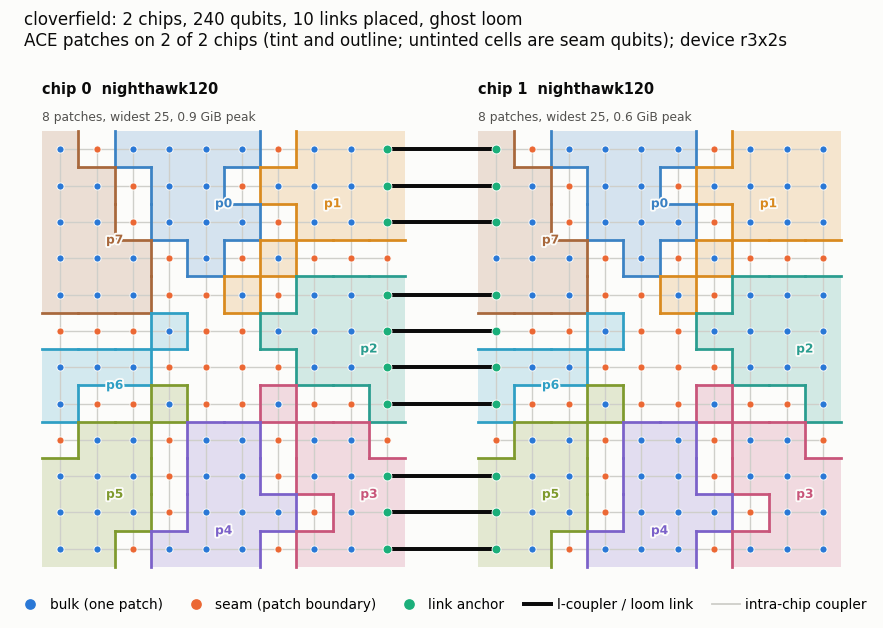


r3t: loom ghost, ghost max width 27
$ python3 nighthawk_qrack.py field plan --repo rcs-nighthawk --device r3t --loom ghost --ace-gpu --gpus 0 --chips-per-gpu 4 --vram-gb 22.03 --gtt 0 --no-ace-error-detection --ghost-max-width 27 --cut-report 4 8 12 16 --png plan_r3t.png
cloverfield: 4 chips ['nighthawk120t', 'nighthawk140', 'nighthawk120t', 'nighthawk140'] on a 2 x 2 grid, 520 qubits
device r3t: Nighthawk r3 as four tiles woven by the loom: 10 x 12 and 10 x 14, all 46 couplers across the two cuts linked, so the field has the 520 qubits and 994 couplers of the 20 x 26 chip; about 245 CZs per cycle, so the device's 10000 two-qubit gates are about 40 cycles of this field
colour   intra-chip CZ   link CZ
  A           260           0
  B           220          13
  C           260           0
  D           208          20
links: 33, loom ghost (13 facing pairs skipped: no colour free at both ends, or no ghost room under the caps)
  chip 0 site (0, 11) -- chip 1 site (0, 0)  colour B
  ch

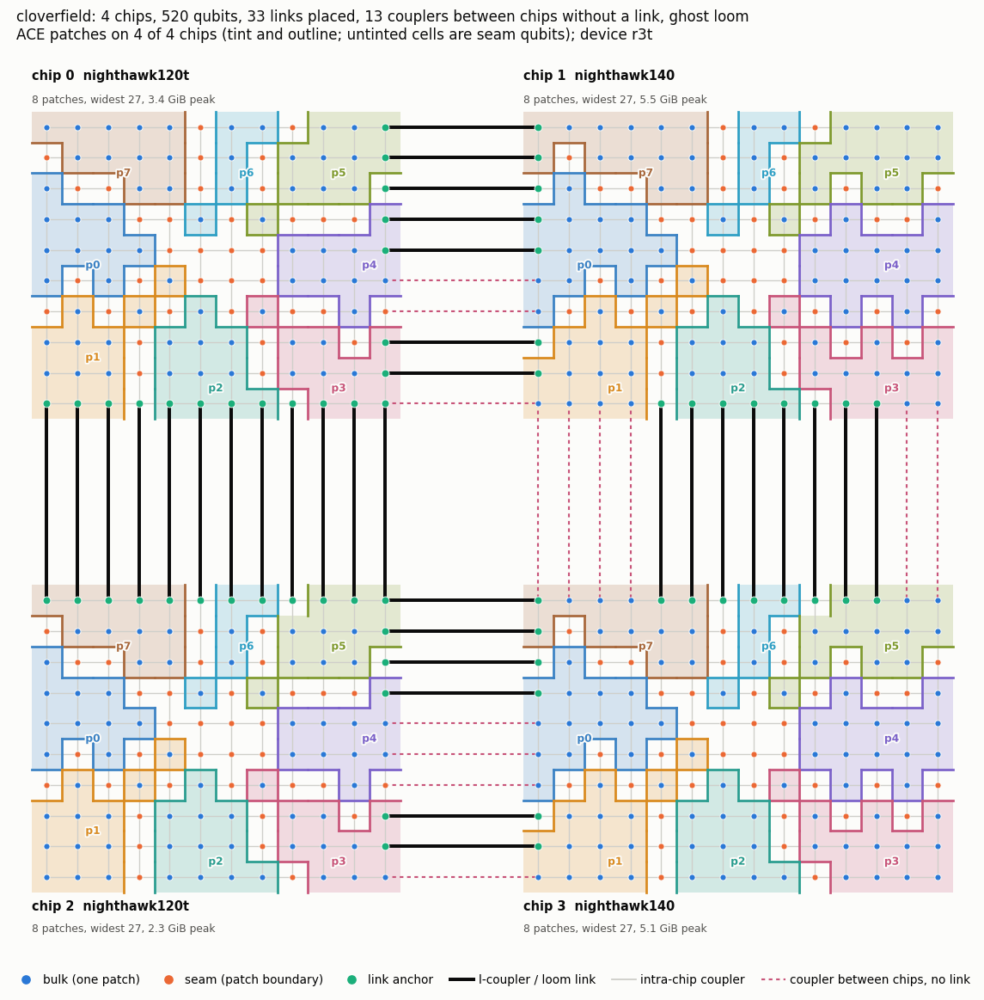


clover6: loom ghost, ghost max width 27
$ python3 nighthawk_qrack.py field plan --repo rcs-nighthawk --device clover6 --loom ghost --ace-gpu --gpus 0 --chips-per-gpu 6 --vram-gb 22.03 --gtt 0 --no-ace-error-detection --ghost-max-width 27 --cut-report 4 8 12 16 --png plan_clover6.png
cloverfield: 6 chips ['nighthawk120', 'nighthawk120', 'nighthawk120', 'nighthawk120', 'nighthawk120', 'nighthawk120'] on a 2 x 3 grid, 720 qubits
device clover6: hypothetical, not an IBM device: six 120-qubit chiplets on a 2 x 3 grid, ten l-couplers per pair (this tool's r3 model before the announcement); about 344 CZs per cycle, so the device's 10000 two-qubit gates are about 29 cycles of this field
colour   intra-chip CZ   link CZ
  A           360           0
  B           288          40
  C           360           0
  D           300          28
links: 68, loom ghost (4 facing pairs skipped: no colour free at both ends, or no ghost room under the caps)
  chip 0 site (0, 9) -- chip 1 site (0, 0)  colou

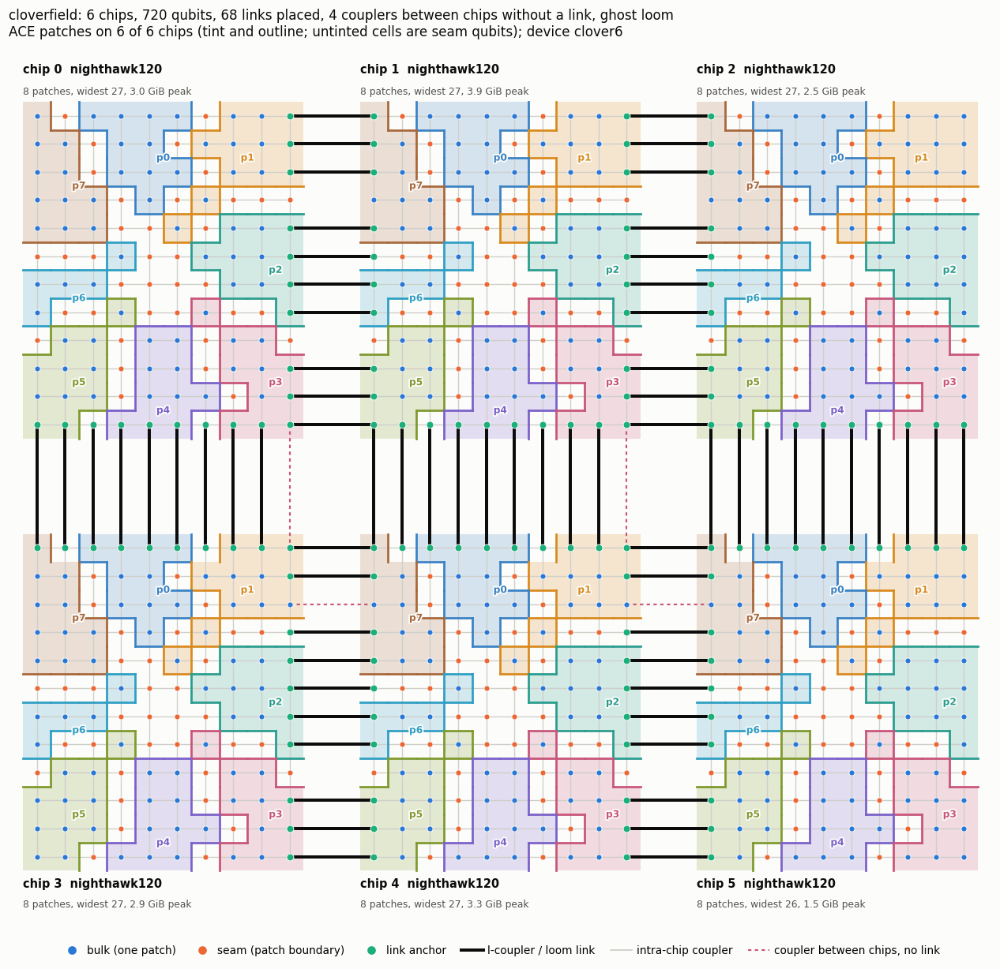


r3x2t: loom ghost, ghost max width 26/3
$ python3 nighthawk_qrack.py field plan --repo rcs-nighthawk --device r3x2t --loom ghost --ace-gpu --gpus 0 --chips-per-gpu 8 --vram-gb 22.03 --gtt 0 --no-ace-error-detection --ghost-max-width 26 --ghost-max-wide 3 --cut-report 4 8 12 16 --png plan_r3x2t.png
cloverfield: 8 chips ['nighthawk120t', 'nighthawk140', 'nighthawk120t', 'nighthawk140', 'nighthawk120t', 'nighthawk140', 'nighthawk120t', 'nighthawk140'] on a 2 x 4 grid, 1040 qubits
device r3x2t: r3x2 as eight tiles: each 520-qubit chip the four r3t tiles (all 46 couplers across its cuts linked), the ten l-couplers between the chips on the rows r3x2 puts them on, so it runs on QrackAceBackend with ACE patches; about 486 CZs per cycle, so the device's 10000 two-qubit gates are about 20 cycles of this field
colour   intra-chip CZ   link CZ
  A           520           0
  B           440          18
  C           520           0
  D           416          32
links: 50, loom ghost (52 facing pa

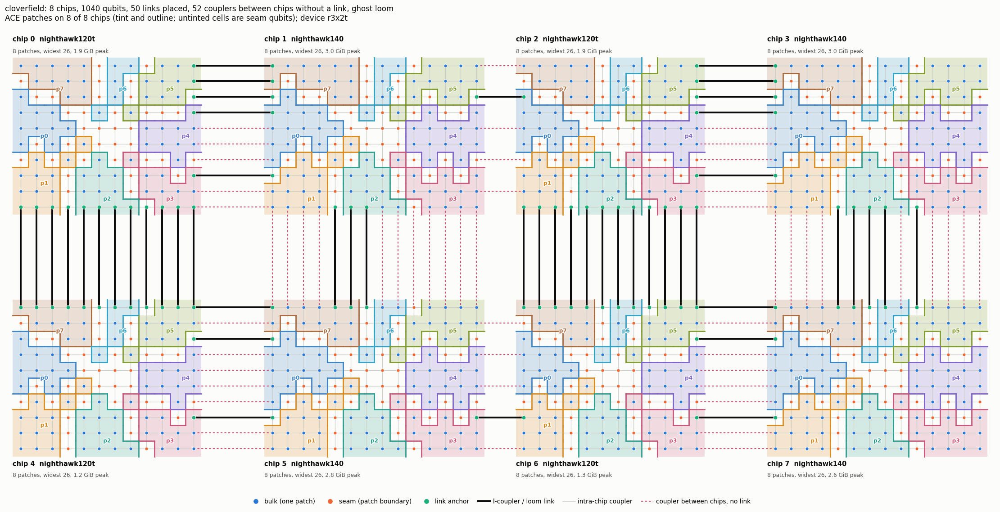

In [8]:
from pathlib import Path
from IPython.display import Image, display

# The plans section 5 chose for r3x2s (240q), r3t (520q tiles), clover6 (720q) and r3x2t (1,040q: IBM's two-chip
# r3x2 as eight tiles): the same arguments the runs below use, so each verdict is about what will run on this host's
# detected RAM / VRAM. Each plan draws its field map: ACE patches per chip, seams, link anchors, the links the loom
# placed and the couplers between chips left without one.
for dev_name, d in PATCH_CONFIG["devices"].items():
    print("\n" + "=" * 78)
    print(f"{dev_name}: loom {d['loom'] or 'none fits'}"
          + (f", ghost max width {ghost_label(d)}" if d["ghost_max_width"] else ""))
    print("=" * 78)
    # --cut-report: gates through ACE seams and the loom per depth, and the empirical fit of the signal (README 3.15)
    run_logged(["python3", "nighthawk_qrack.py", "field", "plan", "--repo", "rcs-nighthawk",
                "--device", dev_name, *d["run_args"], "--cut-report", "4", "8", "12", "16",
                "--png", f"plan_{dev_name}.png"])
    if Path(f"plan_{dev_name}.png").is_file():
        display(Image(f"plan_{dev_name}.png"))
    if not d["runnable"]:
        print(f"NOTE: {dev_name} does not fit this host with any loom "
              f"({'per-device VRAM' if PATCH_CONFIG['stack'] == 'opencl-gpu' else 'host RAM'} budget); "
              "it is skipped by the runs below")


In [9]:
import re

# 1. Quick 61-qubit Nighthawk r2 ACE Hamming simulation using the dimensioned --ace-max-width
ace_max_w = PATCH_CONFIG["ace_max_width"]
run_cmd = [
    "python3", "nighthawk_qrack.py", "run",
    "--repo", "rcs-nighthawk",
    "--backend", "ace",
    "--families", "hamming",
    "--sizes", "61",
    "--depths", "4",
    "--instances", "1",
    "--fold", "1",
    "--ace-max-width", str(ace_max_w),
    "--no-ace-error-detection",
    "--out", "colab_ace_61q.jsonl",
]
if PATCH_CONFIG["stack"] == "opencl-gpu":
    run_cmd += ["--ace-gpu", "--vram-gb", f"{PATCH_CONFIG['vram_gib']:g}"]
else:
    run_cmd += ["--cpu", "--max-rss-gb", f"{PATCH_CONFIG['max_rss_gb']:g}"]
r_ace = run_logged(run_cmd)

# 2. Quick 240-qubit two-chip Nighthawk r3 scaled (r3x2s) field simulation with the planned arguments
d = PATCH_CONFIG["devices"]["r3x2s"]
if d["runnable"]:
    print()
    r_field = run_logged([
        "python3", "nighthawk_qrack.py", "field", "run",
        "--repo", "rcs-nighthawk",
        "--device", "r3x2s",
        "--family", "hamming",
        "--protocol", "nnqab",
        "--fold", "1",
        "--depths", "4",
        "--instances", "1",
        "--out", "colab_r3x2s.jsonl",
        *d["run_args"],   # the planned arguments, --no-ace-error-detection included
    ])
else:
    r_field = None
    print("r3x2s does not fit this host: skipped")

# Summary of both quick runs
print("\n=== Quick runs ===")
# the run's closing table (also printed when the point was already in the .jsonl from an earlier run)
m = re.search(r"^61\s+4\s+1\s+\d+\s+([0-9.]+)", r_ace["out"], re.M)
print(f"  61q ACE, d4:          signal {m.group(1) if m else '?'}  ({r_ace['seconds']:.1f} s)"
      + (f"  FAILED: {failed_points(r_ace['out'])}" if failed_points(r_ace["out"]) else ""))
if r_field:
    m = re.search(r"^n\d+ hamming d4 .*?\bF ([0-9.]+)(.*)$", r_field["out"], re.M)
    extra = re.search(r"chips ([0-9. ]+?)\s+ghost drift ([0-9.]+)", m.group(2)) if m else None
    bad = failed_points(r_field["out"])
    print(f"  r3x2s field, d4:      signal {m.group(1) if m else '?'}"
          + (f", chips {extra.group(1).strip()}, ghost drift {extra.group(2)}" if extra else "")
          + f"  ({r_field['seconds']:.1f} s, loom {d['loom']})" + (f"  FAILED: {bad}" if bad else ""))


$ python3 nighthawk_qrack.py run --repo rcs-nighthawk --backend ace --families hamming --sizes 61 --depths 4 --instances 1 --fold 1 --ace-max-width 30 --no-ace-error-detection --out colab_ace_61q.jsonl --ace-gpu --vram-gb 22.03
Device #0, Building JIT.
# ace n=61 (64 sites), max width 30: lrc=4 lrr=2 torus=False, 31/102 couplers across simulators, 74 on a seam, 22 seam qubits, simulator widths [23, 23, 19, 15, 14, 14, 11], dense worst case 0.1 GB per worker
# note: --ace-gpu with wide patches: each V340 die has 8 GB; patches over ~29 qubits (fp32) will not fit on one
# cfg ace-a33f05d6: backend ace, sizes [61], shots paper, twirls 64, lrc/lrr 4/4, max width 30 (layout per size above)
# 0 of 1 points already done
# progress n61 hamming K1 d4 p0 i0: circuit run 1/1, 100.0% of cycles, elapsed 0m00s, ETA 0m00s
n 61 hamming K1 d  4 part 0 inst 0  F 0.71817 +/- 0.0e+00  (0.4s)

== mirror Hamming-weight signal 1 - 2h of the ace backend (Dan Strano's observable; ideal 1; plain means over insta

### 5.1 Max-Memory Run (largest cloverfield that fits)

Runs the most memory-demanding single-processor cloverfield device (`r3x2s`, `r3t`, `clover6`; `r3x2t` has section 5.3) whose plan fits the detected RAM / VRAM (section 5's table), and reports wall time, the Hamming signal per depth with its standard error over instances, bulk / seam / anchor signals, ghost drift, compute time per depth, and peak memory per GPU (`nvidia-smi` on NVIDIA, amdgpu sysfs on AMD) and on the host, next to what the planner predicted.

| Setting | Default | Meaning |
|---|---|---|
| `RUN_MAX_FIELD` | `True` | `False` skips the run |
| `MAX_RUN_DEPTHS` | `["4", "8", "12", "16"]` | depths of the decay curve |
| `MAX_RUN_INSTANCES` | `1` | random circuit instances per depth |
| `MAX_RUN_DEPTH_INSTANCES` | `{"12": 3, "16": 3}` | per-depth override: deep points, where the signal approaches zero, get more instances for error bars |
| `MAX_RUN_TIMEOUT_S` | `14400` | limit per `field run` call |
| `MEM_TRACE` | `True` | memory trace per run: `<records>.mem.csv` and `<records>.mem.png`, peaks per depth in the table |
| `MEM_TRACE_PER_WORKER` | `True` | GPU memory per chip worker (NVIDIA, `nvidia-smi --query-compute-apps`) |

Depths that share an instance count run as one `field run` call; all calls write to the same `.jsonl`. The configuration tag does not include the instance count, so a later call (or a rerun of this cell after a timeout) adds to the same configuration and skips points already recorded. Compute time grows with depth and instances: on an A100 80GB, clover6 took about 63 / 302 / 582 / 910 s per instance at d4 / d8 / d12 / d16.


**Graphs.** After the run come the plan's field map (`<records>.plan.png`, ACE patches per chip) and the one-page poster of the records (`<records>.poster.png`, `nighthawk_graph.py --poster`: the field with its patches, signal against depth and by region, per-chip signal, links per pair).

**Memory trace.** Every `SAMPLE_EVERY_S` the run records used memory per GPU and on the host, the depth being run (from the run's progress lines) and, on NVIDIA, each chip worker's GPU memory. The summary table gains a GPU and a host column: the peak above the level before the run while that depth was running. Below it come the peak against the plan in percent, each chip worker's peak (by start order), and a warning when a GPU reached 90 % of its memory. The plot shows the device and host totals with the depths shaded, the planned figure (dashed, one GPU or CPU runs) and the device size (dotted); the per-worker panel appears when `nvidia-smi` lists the processes (in some containers it lists none). The CSV is the plot's table view.

**`PLAN_SCALE`** (section 5's sizing cell, default `1.0`) checks the cloverfield plans against that multiple of the detected budget. The plan counts every patch dense, as the runs allocate it (no error-detection ancilla), plus one compose buffer per chip at once; a scale above 1.0 lets the planner choose wider ghost caps and the tile search wider patches, at the risk of the chips' compose buffers coinciding. The widest single patch stays bounded by the device's max allocation. Use the trace to check a scaled run: the 90 % warning means the scale is too high for that workload.

The plot keeps its legend outside the plot area, right of each panel; the planned (dashed) and device (dotted) lines are labelled at their right end.

Max-memory run: clover6: 720 qubits, 6 chip(s), loom ghost, ghost max width 27, 68 links, planned 17.10 GiB on 1 GPU(s), 6 chip(s) per GPU
  depths x instances: d4 x 1, d8 x 1, d12 x 3, d16 x 3

$ python3 nighthawk_qrack.py field run --repo rcs-nighthawk --device clover6 --family hamming --protocol nnqab --fold 1 --depths 4 8 --instances 1 --out colab_max_clover6.jsonl --loom ghost --ace-gpu --gpus 0 --chips-per-gpu 6 --vram-gb 22.03 --gtt 0 --no-ace-error-detection --ghost-max-width 27
# --protocol nnqab: single-qubit ensemble set to nnqab (as nn_qab.py)
# cloverfield field-5b42c2e7: 6 chips ['nighthawk120', 'nighthawk120', 'nighthawk120', 'nighthawk120', 'nighthawk120', 'nighthawk120'] (2x3), 720 qubits, 68 links (4 facing pairs skipped: no common free colour, or no ghost room under the caps), loom ghost, backend ace, theta nnqab, family hamming, protocol nnqab
# looms: 1 on GPUs 0, 0 on the CPU; 2 points
Device #0, Building JIT.
Device #0, Building JIT.
Device #0, Building JIT.
Devi

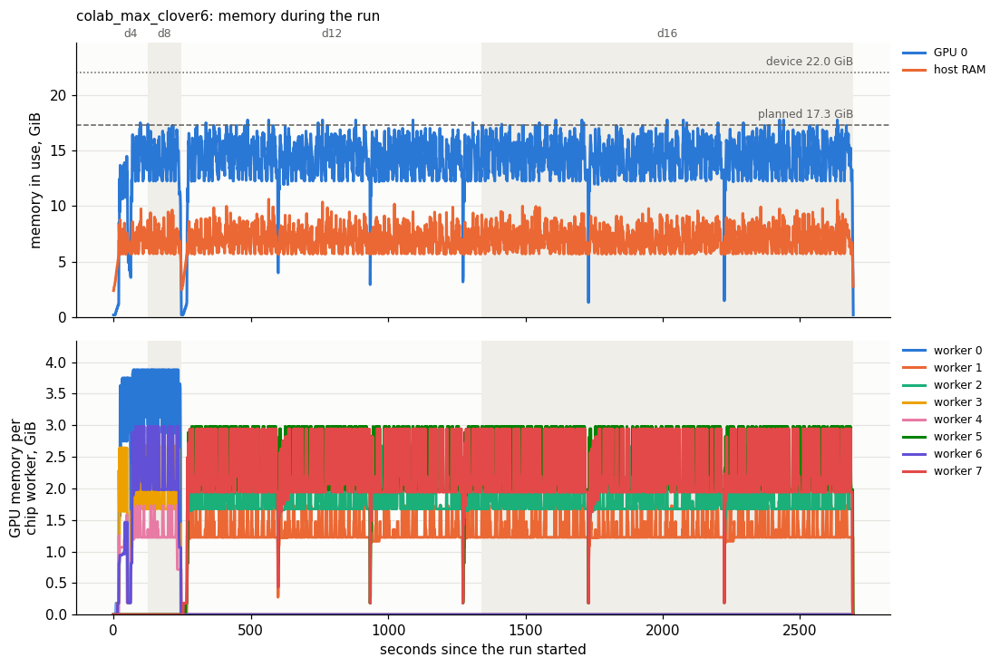

  memory trace         colab_max_clover6.mem.csv, colab_max_clover6.mem.png (2560 samples)
  records              colab_max_clover6.jsonl
  colab_max_clover6.plan.png


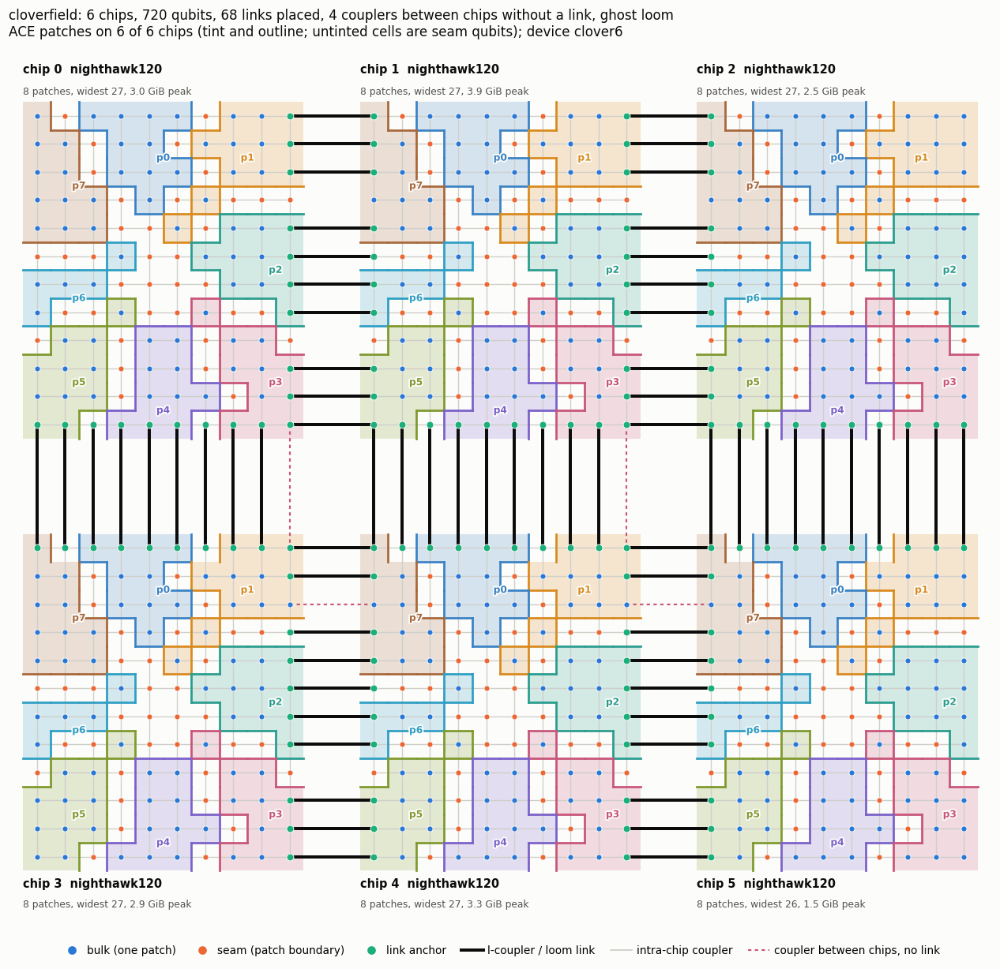

  colab_max_clover6.poster.png


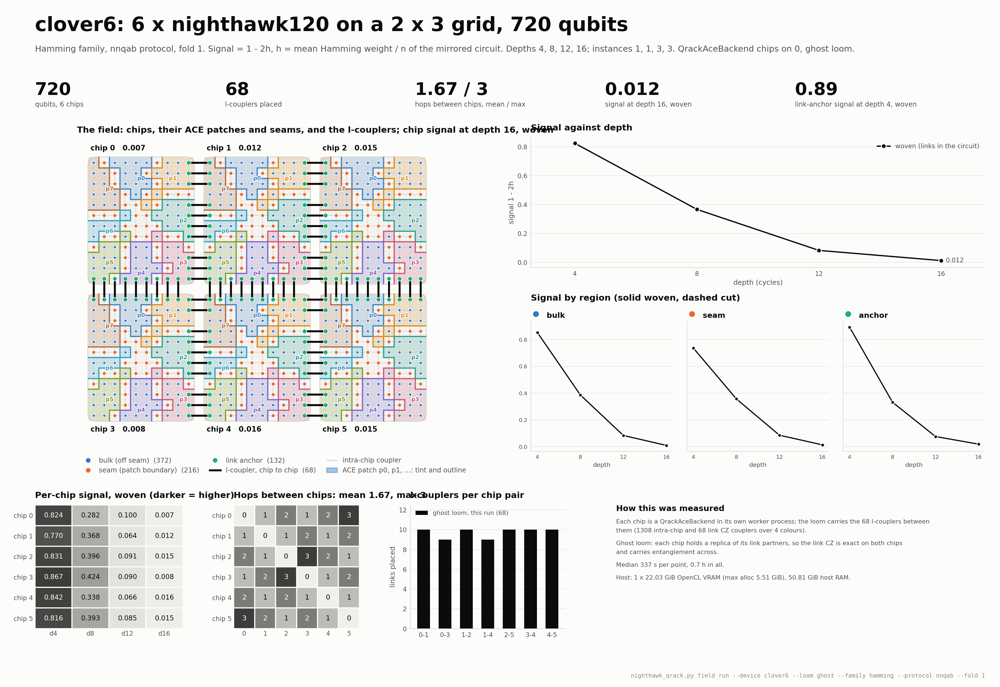

In [10]:
import re
import shutil
import subprocess
import threading
import time
from pathlib import Path
from IPython.display import Image, display

# Largest cloverfield run that the detected RAM / VRAM holds, measured: wall time, signal, peak memory
RUN_MAX_FIELD = True          # set False to skip (the functions below are still defined for section 5.2)
MAX_RUN_DEPTHS = ["4", "8", "12", "16"]       # decay curve; time grows with depth
MAX_RUN_INSTANCES = 1                         # random circuit instances at every depth ...
MAX_RUN_DEPTH_INSTANCES = {"12": 3, "16": 3}  # ... except these, where the signal nears zero and needs error bars
MAX_RUN_TIMEOUT_S = 4 * 3600  # per field run call; a stopped or rerun cell resumes from the .jsonl
SAMPLE_EVERY_S = 1.0          # memory sampling interval
MEM_TRACE = True              # save each run's memory trace (CSV + plot) and show peaks per depth
MEM_TRACE_PER_WORKER = True   # per chip-worker GPU memory (NVIDIA only, nvidia-smi --query-compute-apps)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

gpu = PATCH_CONFIG["stack"] == "opencl-gpu"
NUM = r"-?(?:\d+\.?\d*|\.\d+)(?:[eE][-+]?\d+)?|nan|inf|-inf"


def planned_gib(d):
    return d["plan_gib"] if gpu else (d["host_gib"] if d["host_gib"] is not None else d["plan_gib"])


def parse_hamming_table(out: str) -> dict:
    """Rows of the run's closing '== cloverfield Hamming signal' table, by depth: instances, mean signal and
    its standard error, bulk / seam / anchor, per-chip means, drift (None for the mean-field loom)."""
    rows = {}
    for block in re.split(r"^== cloverfield Hamming signal.*$", out, flags=re.M)[1:]:
        seen = False
        for line in block.splitlines():
            # d  lam  circ  broken  signal +/- se  bulk  seam  anchor  chip1 .. chipN  drift
            parts = line.split()
            if len(parts) >= 12 and parts[0].isdigit() and parts[5] == "+/-":
                seen = True
                num = lambda x: x if re.fullmatch(NUM, x) else None   # no links: anchor / drift print a dash
                rows[int(parts[0])] = dict(
                    lam=int(parts[1]), inst=int(parts[2]), broken=int(parts[3]), signal=parts[4], se=parts[6],
                    bulk=parts[7], seam=parts[8], anchor=num(parts[9]), chips=" ".join(parts[10:-1]),
                    drift=num(parts[-1]))
            elif seen and line.strip():
                break                                  # first line after the table
    return rows


def depth_seconds(out: str) -> dict:
    """Summed compute seconds per depth from the per-point lines (n<N> hamming d<D> ... (<s> s, loom ...))."""
    secs = {}
    for m in re.finditer(r"^n\d+ hamming d(\d+) .*\((" + NUM + r") s, loom", out, re.M):
        secs[int(m.group(1))] = secs.get(int(m.group(1)), 0.0) + float(m.group(2))
    return secs


def nvidia_worker_mem_gib() -> dict:
    """GPU memory per process (pid -> GiB) from nvidia-smi --query-compute-apps; {} where it lists none
    (no NVIDIA GPU, or a container whose PID namespace hides the processes)."""
    if not shutil.which("nvidia-smi"):
        return {}
    try:
        res = subprocess.run(["nvidia-smi", "--query-compute-apps=pid,used_memory", "--format=csv,noheader,nounits"],
                             capture_output=True, text=True, timeout=10)
    except (subprocess.SubprocessError, OSError):
        return {}
    out = {}
    for line in res.stdout.strip().splitlines():
        parts = [p.strip() for p in line.split(",")]
        if len(parts) >= 2 and parts[0].isdigit():
            try:
                out[int(parts[0])] = out.get(int(parts[0]), 0.0) + float(parts[1]) / 1024.0
            except ValueError:
                pass
    return out


def _proc_start(pid: int) -> int:
    try:
        return int(open(f"/proc/{pid}/stat").read().rsplit(")", 1)[1].split()[19])
    except (OSError, ValueError, IndexError):
        return 0


def _is_chipworker(pid: int) -> bool:
    try:
        return b"chipworker" in open(f"/proc/{pid}/cmdline", "rb").read()
    except OSError:
        return False


def save_mem_trace(trace: list, keys: list, labels: dict, workers: list, planned: float, capacity, stem: str):
    """Write the trace as <stem>.mem.csv and plot it as <stem>.mem.png (device / host totals, and per chip
    worker below when known), with the depth being run shaded; shows the plot in the notebook."""
    import csv
    import matplotlib
    import matplotlib.pyplot as plt
    from IPython.display import Image, display
    cols = [str(k) for k in keys] + [f"worker{i}" for i in range(len(workers))]
    with open(f"{stem}.mem.csv", "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["t_s", "depth"] + [labels.get(k, str(k)).replace(" ", "_") for k in keys]
                   + [f"worker{i}_gib" for i in range(len(workers))])
        for row in trace:
            w.writerow([f"{row['t']:.1f}", row["depth"] or ""] + [f"{row['mem'].get(k, ''):.3f}" if k in row["mem"] else ""
                                                                    for k in keys]
                       + [f"{row['workers'].get(p, 0.0):.3f}" for p in workers])
    t = [r["t"] for r in trace]
    panels = 2 if workers else 1
    fig, axes = plt.subplots(panels, 1, figsize=(10, 3.4 * panels), sharex=True, squeeze=False)
    axes = axes[:, 0]
    for ax in axes:
        ax.set_facecolor("#fcfcfb")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
        ax.set_axisbelow(True)
        # depth bands: alternating light shading, depth label at the top of each band
        i0, shade = 0, False
        for i in range(1, len(trace) + 1):
            if i == len(trace) or trace[i]["depth"] != trace[i0]["depth"]:
                if trace[i0]["depth"]:
                    if shade:
                        ax.axvspan(t[i0], t[min(i, len(t) - 1)], color="#efeee9", lw=0)
                    if ax is axes[0]:
                        ax.text((t[i0] + t[min(i, len(t) - 1)]) / 2, 1.01, f"d{trace[i0]['depth']}",
                                transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8, color="#5f5e5a")
                    shade = not shade
                i0 = i
    ax = axes[0]
    top = 0.0
    for j, k in enumerate(keys):
        ys = [r["mem"].get(k, float("nan")) for r in trace]
        top = max([top] + [y for y in ys if y == y])
        ax.plot(t, ys, color=SERIES[j % len(SERIES)], lw=2, label=labels.get(k, str(k)))
    # reference lines labelled at their right end, above the line; the legend sits outside the plot, right of
    # it, so neither covers the other or the data
    x_end = t[-1] if t else 1.0
    for val, ls, txt in ((planned, "--", "planned"), (capacity, ":", "device")):
        if val:
            top = max(top, val)
            ax.axhline(val, color="#5f5e5a", lw=1, ls=ls)
            ax.annotate(f"{txt} {val:.1f} GiB", (x_end, val), xytext=(0, 3), textcoords="offset points",
                        ha="right", va="bottom", fontsize=8, color="#5f5e5a")
    ax.set_ylim(0, max(top, 1e-3) * 1.12)
    ax.set_ylabel("memory in use, GiB")
    ax.set_title(f"{stem}: memory during the run", loc="left", fontsize=10, pad=16)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8, frameon=False, borderaxespad=0)
    if workers:
        ax = axes[1]
        wtop = 0.0
        for i, p in enumerate(workers):
            ys = [r["workers"].get(p, 0.0) for r in trace]
            wtop = max([wtop] + ys)
            ax.plot(t, ys, color=SERIES[i % len(SERIES)], lw=2, label=f"worker {i}")
        ax.set_ylim(0, max(wtop, 1e-3) * 1.12)
        ax.set_ylabel("GPU memory per\nchip worker, GiB")
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8, frameon=False, borderaxespad=0)
    axes[-1].set_xlabel("seconds since the run started")
    fig.tight_layout()
    fig.savefig(f"{stem}.mem.png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    display(Image(f"{stem}.mem.png"))


def bench_field(label: str, d: dict, out_file: str, depths=None, instances=None, depth_instances=None,
                timeout=None, trace_stem=None) -> dict:
    """Run one sized field (an entry of PATCH_CONFIG['devices'] or size_field's result) over the depths,
    one `field run` call per instance count, all into out_file, while sampling per-GPU and host memory.
    Prints the per-depth table and the memory against the plan; returns rows, seconds and peaks. The memory
    trace is saved as <trace_stem>.mem.csv / .mem.png (default: the records' name)."""
    depths = MAX_RUN_DEPTHS if depths is None else depths
    instances = MAX_RUN_INSTANCES if instances is None else instances
    depth_instances = MAX_RUN_DEPTH_INSTANCES if depth_instances is None else depth_instances
    timeout = MAX_RUN_TIMEOUT_S if timeout is None else timeout
    # one field run call per instance count, all into the same .jsonl: the config tag does not include
    # --instances, so each call adds its points to the same configuration (and skips points already done)
    groups = {}
    for dep in depths:
        groups.setdefault(int(depth_instances.get(dep, instances)), []).append(dep)
    print(f"{label}: {d['qubits'] or '?'} qubits, {d['n_chips']} chip(s), loom {d['loom']}"
          + (f", ghost max width {ghost_label(d)}" if d["ghost_max_width"] else "")
          + f", {d['links']} links, planned {planned_gib(d):.2f} GiB on "
          + (f"{len(PATCH_CONFIG['gpu_indices'])} GPU(s), {d['chips_per_gpu']} chip(s) per GPU" if gpu else "the CPU"))
    print("  depths x instances: " + ", ".join(f"d{dep} x {n}" for n, deps in groups.items() for dep in deps))

    base = device_mem_used_gib(OCL_DEVS)
    peak = dict(base)
    stop = threading.Event()
    state = dict(depth=None)
    trace, t_start = [], time.time()
    depth_peak = {}                      # depth -> {key: peak GiB}
    pre_pids = set(nvidia_worker_mem_gib()) if (gpu and MEM_TRACE_PER_WORKER) else set()

    def on_line(line):
        # the depth a run is on: from its progress and per-point lines
        m = re.match(r"^# progress (?:n\d+ )?\S+ .*?\bd(\d+)\b", line) or re.match(r"^n\d+ hamming d(\d+) ", line)
        if m:
            state["depth"] = int(m.group(1))

    def sample():
        while not stop.is_set():
            mem = device_mem_used_gib(OCL_DEVS)
            for k, v in mem.items():
                peak[k] = max(peak.get(k, v), v)
            wk = {}
            if gpu and MEM_TRACE_PER_WORKER:
                wk = {p: v for p, v in nvidia_worker_mem_gib().items() if p not in pre_pids and _is_chipworker(p)}
            dep = state["depth"]
            if dep is not None:
                dp = depth_peak.setdefault(dep, {})
                for k, v in mem.items():
                    dp[k] = max(dp.get(k, v), v)
            if MEM_TRACE:
                trace.append(dict(t=time.time() - t_start, depth=dep, mem=mem, workers=wk))
            stop.wait(SAMPLE_EVERY_S)

    th = threading.Thread(target=sample, daemon=True)
    th.start()
    runs = []
    try:
        for n_inst, deps in sorted(groups.items(), key=lambda g: min(int(x) for x in g[1])):
            cmd = ["python3", "nighthawk_qrack.py", "field", "run", "--repo", "rcs-nighthawk", *d["field_args"],
                   "--family", "hamming", "--protocol", "nnqab", "--fold", "1",
                   "--depths", *deps, "--instances", str(n_inst),
                   "--out", out_file, *d["run_args"]]   # run_args carry --no-ace-error-detection (RUN_ARGS_ED)
            print()
            state["depth"] = min(int(x) for x in deps)   # a call runs its depths in order; progress lines move it on
            runs.append(run_logged(cmd, timeout=timeout, on_line=on_line))
            if runs[-1]["timed_out"]:
                break
    finally:
        stop.set()
        th.join()

    rows, secs = {}, {}
    for r in runs:
        rows.update(parse_hamming_table(r["out"]))
        for k, v in depth_seconds(r["out"]).items():
            secs[k] = secs.get(k, 0.0) + v
    wall = sum(r["seconds"] for r in runs)
    failed = [failed_points(r["out"]) for r in runs if failed_points(r["out"])]

    print(f"\n=== {label} ===")
    print(f"  wall time {wall:.1f} s" + ("  (TIMED OUT: rerun the cell to resume)" if any(r["timed_out"] for r in runs) else ""))
    for f in failed:
        print(f"  FAILED: {f}")
    gpu_keys = [k for k in peak if k != "host"]

    def dpk(dep, which):
        dp = depth_peak.get(dep, {})
        if which == "gpu":
            v = [dp[k] - base.get(k, 0) for k in gpu_keys if k in dp]
            return f"{sum(v):.2f}" if v else "-"
        return f"{dp['host'] - base.get('host', 0):.2f}" if "host" in dp else "-"

    print(f"  {'d':>3s} {'inst':>4s} {'signal':>9s} {'+/- se':>8s} {'bulk':>8s} {'seam':>8s} {'anchor':>8s} "
          f"{'drift':>7s} {'compute s':>9s} {'GPU GiB':>8s} {'host GiB':>8s}  chip signals (means)")
    # compute s: points run by this call (points already in the .jsonl were not rerun and add nothing);
    # GPU / host GiB: peak in use above the level before the run, while that depth was running
    for dep in sorted(rows):
        w = rows[dep]
        print(f"  {dep:3d} {w['inst']:4d} {w['signal']:>9s} {w['se']:>8s} {w['bulk']:>8s} {w['seam']:>8s} "
              f"{w['anchor'] or '-':>8s} {w['drift'] or '-':>7s} {secs.get(dep, 0.0):9.1f} "
              f"{dpk(dep, 'gpu'):>8s} {dpk(dep, 'host'):>8s}  {w['chips']}")
    if not rows:
        print("  (no closing table in the run output)")
    print(f"\n  {'memory':20s} {'before':>8s} {'peak':>8s} {'run used':>9s}  (GiB)")
    labels = {d_["index"]: f"GPU {d_['index']} {d_['device'][:12]}" for d_ in OCL_DEVS}
    for k in sorted(peak, key=lambda k: (k == "host", str(k))):
        print(f"  {('host RAM' if k == 'host' else labels.get(k, str(k))):20s} {base.get(k, 0):8.2f} "
              f"{peak[k]:8.2f} {peak[k] - base.get(k, 0):9.2f}")
    if gpu and not any(k != "host" for k in peak):
        print("  (no per-GPU memory counter readable here: neither nvidia-smi nor amdgpu sysfs)")
    print(f"  planned              {planned_gib(d):.2f} GiB per loom (sum of the chips' peaks, "
          "nighthawk_qrack.py field plan)"
          + (f", PLAN_SCALE {PATCH_CONFIG.get('plan_scale', 1.0):g}" if PATCH_CONFIG.get("plan_scale", 1.0) != 1.0 else ""))
    used = {k: peak[k] - base.get(k, 0) for k in peak}
    if planned_gib(d):
        used_main = sum(v for k, v in used.items() if k != "host") if gpu else used.get("host", 0.0)
        print(f"  peak / planned       {100 * used_main / planned_gib(d):.0f} %")
    cap = None
    if gpu:
        caps = [dv["global_mem_gib"] for dv in OCL_DEVS if dv["index"] in gpu_keys]
        cap = max(caps) if caps else PATCH_CONFIG.get("vram_gib")
        worst = max((peak[k] / dv["global_mem_gib"] for dv in OCL_DEVS for k in gpu_keys
                     if dv["index"] == k and dv["global_mem_gib"]), default=0.0)
        if worst > 0.9:
            print(f"  WARNING              a GPU reached {100 * worst:.0f} % of its memory: lower PLAN_SCALE")
    workers = []
    if trace:
        pids = sorted({p for r in trace for p in r["workers"]}, key=_proc_start)
        workers = pids
        if pids:
            print("  per chip worker (GPU, by start order; a loom restarts its workers per point, so a worker index "
                  "can cover several processes):")
            for i, p in enumerate(pids):
                print(f"    worker {i} (pid {p}): peak {max(r['workers'].get(p, 0.0) for r in trace):.2f} GiB")
        elif gpu and MEM_TRACE_PER_WORKER:
            print("  (no per-worker GPU memory: nvidia-smi lists no compute processes here)")
        stem = trace_stem or Path(out_file).with_suffix("").name
        save_mem_trace(trace, sorted(peak, key=lambda k: (k == "host", str(k))),
                       {**{dv["index"]: f"GPU {dv['index']}" for dv in OCL_DEVS}, "host": "host RAM"},
                       workers[:len(SERIES)],
                       # the plan is one total: drawn only where one line carries it (one GPU, or the CPU host)
                       (planned_gib(d) + base[gpu_keys[0]] if len(gpu_keys) == 1 else None) if gpu
                       else planned_gib(d) + base.get("host", 0),
                       cap, stem)
        print(f"  memory trace         {stem}.mem.csv, {stem}.mem.png ({len(trace)} samples)")
    print(f"  records              {out_file}")
    return dict(rows=rows, secs=secs, wall=wall, used=used, failed=failed, depth_peak=depth_peak, base=base,
                timed_out=any(r["timed_out"] for r in runs))


def field_graphs(d: dict, out_file: str, note: str = "") -> None:
    """The run's graphs: the plan's field map (ACE patches, seams, link anchors, the links the loom placed and the
    couplers between chips without one) and the one-page poster of the records (nighthawk_graph.py --poster:
    signal against depth, by region, per chip, the field with its patches)."""
    stem = Path(out_file).with_suffix("").name
    try:
        run_logged(["python3", "nighthawk_qrack.py", "field", "plan", "--repo", "rcs-nighthawk", *d["field_args"],
                    *d["run_args"], "--png", f"{stem}.plan.png"], echo=False, quiet=True)
    except subprocess.CalledProcessError:
        print("  plan graph: field plan failed (see above)")
    cmd = ["python3", "nighthawk_graph.py", "--repo", "rcs-nighthawk", "--out", out_file, "--poster", f"{stem}.poster.png",
           "--poster-note", f"Host: {PATCH_CONFIG['budget_summary']}." + (f" {note}" if note else "")]
    if PATCH_CONFIG["stack"] == "opencl-gpu":
        cmd += ["--vram-gb", f"{plan_vram_gib(PATCH_CONFIG):g}"]
    try:
        run_logged(cmd, echo=False, quiet=True)
    except subprocess.CalledProcessError:
        print("  poster: nighthawk_graph.py failed (see above)")
    for png in (f"{stem}.plan.png", f"{stem}.poster.png"):
        if Path(png).is_file():
            print(f"  {png}")
            display(Image(filename=png))


# 5.1 takes the single-processor fields; the 1,040-qubit r3x2t has its own run in section 5.3
cands = [(n, d) for n, d in PATCH_CONFIG["devices"].items() if d["runnable"] and n != "r3x2t"]
if not RUN_MAX_FIELD:
    print("RUN_MAX_FIELD is False: skipped")
elif not cands:
    print("No cloverfield device fits this host's detected budget: nothing to run")
else:
    # the most demanding plan that fits, ghost loom before mean-field at equal memory
    name, d = max(cands, key=lambda nd: (planned_gib(nd[1]), nd[1]["loom"] == "ghost"))
    MAX_RUN_SPEC = dict(field_args=list(d["field_args"]), run_args=list(d["run_args"]),
                        out_file=f"colab_max_{name}.jsonl")
    MAX_RUN_RESULT = bench_field(f"Max-memory run: {name}", d, MAX_RUN_SPEC["out_file"])
    field_graphs(d, MAX_RUN_SPEC["out_file"])


### 5.2 Tile Scaling Benchmark (1, 2 and 4 tiles of Nighthawk r3)

The 520-qubit r3 chip (20 x 26) cut into the tiles of `nighthawk_qrack.py`'s `r3t` preset and woven back together by the loom.

| Tiles | Tile types | Grid | Qubits | Inter-tile couplers |
|---|---|---|---|---|
| 1 | 10 x 12 | 1 x 1 | 120 | none |
| 2 | 10 x 12 + 10 x 14 (the 10 x 26 half chip) | 1 x 2 | 260 | the 10 across the cut, as many as fit |
| 4 | 10 x 12, 10 x 14, twice (the whole chip) | 2 x 2 | 520 | the 46 across both cuts, as many as fit |

**Layout search before each tile count.** The stored tiles (`nighthawk120t`, `nighthawk140`) were made for 8 GB dies (patch cap 27, two patches at it). Before each tile count runs, the cell works out how much memory one tile gets on this machine (its device's VRAM less a 0.5 GiB reserve per worker, split between the tiles on that device; on a CPU runtime the host budget split between the tiles) and the widest patch cap that share allows (Qrack's 3x rule on a GPU, patch plus compose transient on the CPU, within the max single allocation). Layout caps count the error-detection ancilla, which the runs leave out, so a cap of W is a simulator of W - 1 qubits. Where that cap is above 27, `nighthawk_qrack.py layoutsearch --lattice` searches each tile type on its own 10 x 12 or 10 x 14 lattice at that cap, one round per objective in `LAYOUT_OBJECTIVES` (fewest couplers through a boundary, which sets the cut load the signal follows (README 3.15); fewest boundary qubits). Each round covers the tiles' 184-site register plus `LAYOUT_AUTO_GEOMETRIES` other geometries, `LAYOUT_CANDIDATES` layouts each, warm-started from the stored tile, and ranks its candidates together with the best so far (`--compare`; the stored tile in the first round) by the benchmark's own observable, the Hamming signal (`nnqab`, no error-detection ancilla) at `LAYOUT_TEST_DEPTHS`. A searched layout therefore replaces a stored tile only when it measures better; a candidate whose test crashes ranks last.

The whole field is then planned with the winning tiles; they are used when the plan fits and, for 2 and 4 tiles, places at least as many inter-tile links as the stored tiles (a coupler without a link is left out of the circuit).

**Mean-loom fallback.** Searched tiles that fit but place fewer links on the ghost loom are planned on the mean-field loom as well, which keeps every inter-tile coupler (as a mean field, no entanglement across it). That field and the stored tiles' field each run `COMPARE_INSTANCES` instances at depth `COMPARE_DEPTH` (Hamming, nnqab, no error detection), and the higher mean signal is used; the comparison table at the end of the cell lists both. Its points go into the same `.jsonl` as the benchmark of that field, so they count toward it. If the stored tiles win, or the mean-field loom does not fit, the cap steps down (`LAYOUT_MAX_ATTEMPTS`), and the stored tiles remain the fallback.

| Setting | Default | Meaning |
|---|---|---|
| `RUN_LAYOUT_SEARCH` | `True` | `False` runs the stored tiles only |
| `LAYOUT_OBJECTIVES` | `["bcz,seam,couplers", "seam,bcz,couplers"]` | one search round each (`layoutsearch --objective`) |
| `LAYOUT_CPSAT_TIME` | `300` | seconds per CP-SAT solve |
| `LAYOUT_CANDIDATES` | `2` | distinct layouts per geometry |
| `LAYOUT_AUTO_GEOMETRIES` | `1` | auto geometries besides the 184-site register (`LAYOUT_EXTRA_SITES` sets their range) |
| `LAYOUT_MAX_WIDE` | `2` | patches allowed at the cap |
| `LAYOUT_MAX_WIDTH` | `None` | the machine's cap, or a lower number (wider patches are slower to simulate) |
| `LAYOUT_MAX_ATTEMPTS` | `2` | caps tried per tile count |
| `LAYOUT_TEST_DEPTHS` | `["4", "8"]` | Hamming-signal test that ranks candidates and the stored tile (`[]`: CP-SAT objective only, which does not predict the signal) |
| `LAYOUT_TEST_INSTANCES` | `2` | circuit instances per test depth |
| `RUN_MEAN_FALLBACK` | `True` | `False`: searched tiles with fewer ghost links step down to the next cap without the comparison |
| `COMPARE_DEPTH` | `"8"` | depth of the mean-loom comparison |
| `COMPARE_INSTANCES` | `3` | circuit instances of each side of the comparison |

A search is done once per tile type and cap and kept in `tile_layouts/` (a tile type searched for 2 tiles is reused for 4 tiles at the same cap, and a rerun of the cell reuses it). The CP-SAT part runs on the CPU cores; the circuit tests and the benchmark runs use the GPU. Per tile type and cap the solving is at most `len(LAYOUT_OBJECTIVES)` x (1 + `LAYOUT_AUTO_GEOMETRIES`) x `LAYOUT_CANDIDATES` x `LAYOUT_CPSAT_TIME`, 40 minutes with the defaults (geometries that cannot hold the tile take seconds), plus the tests.

The 4-tile stored layout runs as `--device r3t`; when section 5.1 already ran that field with the same arguments, its records are reused instead of rerunning it.

Depths, instances and the timeout of the benchmark runs follow section 5.1's settings unless `TILE_DEPTHS`, `TILE_INSTANCES`, `TILE_DEPTH_INSTANCES` or `TILE_TIMEOUT_S` are set here. The cell prints the layouts used against the stored tiles (boundary qubits, couplers through a boundary, widths), each tile count's sizing, and a closing table of signal per depth, wall time and peak GPU and host memory against the plan.


Sizing each tile count for this machine (1 x 22.03 GiB OpenCL VRAM (max alloc 5.51 GiB), 50.81 GiB host RAM)...

1 tile(s): 21.53 GiB per tile -> patch cap 30 (simulators 29 qubits, no error-detection ancilla)

  tile 120 (10x12, 120 qubits) at cap 30x2: 2 round(s) of up to 2 geometries x 2 candidates x 300 s of CP-SAT (at most 40 min; geometries that cannot hold the tile take seconds), each ranked against the best so far by the Hamming signal at depths 4, 8 (2 instance(s))

  round 0: objective bcz,seam,couplers, against nighthawk120t
$ python3 nighthawk_qrack.py layoutsearch --repo rcs-nighthawk --n 120 --lattice 10x12 --geometries 184:2:7 auto --max-geometries 1 --extra-sites 80 --max-width 30 --max-wide 2 --objective bcz,seam,couplers --hint nighthawk120t --compare nighthawk120t --candidates 2 --cpsat-time 300 --test-depths 4 8 --test-family hamming --test-protocol nnqab --test-no-ace-error-detection --test-instances 2 --test-jobs 1 --outdir /content/thereminq-examples/devices/anno

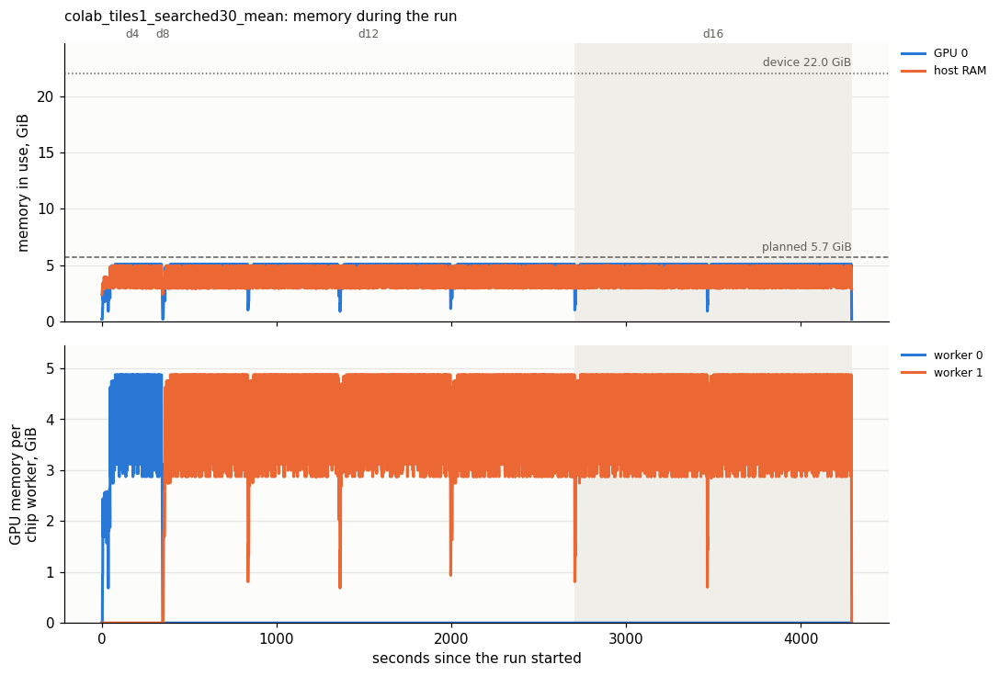

  memory trace         colab_tiles1_searched30_mean.mem.csv, colab_tiles1_searched30_mean.mem.png (4115 samples)
  records              colab_tiles1_searched30_mean.jsonl

Tile benchmark: 2 tile(s), searched layout: 260 qubits, 2 chip(s), loom mean, 10 links, planned 14.60 GiB on 1 GPU(s), 2 chip(s) per GPU
  depths x instances: d4 x 1, d8 x 1, d12 x 3, d16 x 3

$ python3 nighthawk_qrack.py field run --repo rcs-nighthawk --chips t120w29n2r1-184-27-c1,t140w29n2r1-184-27-c0 --arrangement 1x2 --links all --family hamming --protocol nnqab --fold 1 --depths 4 8 --instances 1 --out colab_tiles2_searched29_mean.jsonl --loom mean --ace-gpu --gpus 0 --chips-per-gpu 2 --vram-gb 22.03 --gtt 0 --no-ace-error-detection
# --protocol nnqab: single-qubit ensemble set to nnqab (as nn_qab.py)
# cloverfield field-e1582a7e: 2 chips ['t120w29n2r1-184-27-c1', 't140w29n2r1-184-27-c0'] (1x2), 260 qubits, 10 links, loom mean, backend ace, theta nnqab, family hamming, protocol nnqab
# looms: 1 on GPUs 0, 0 on t

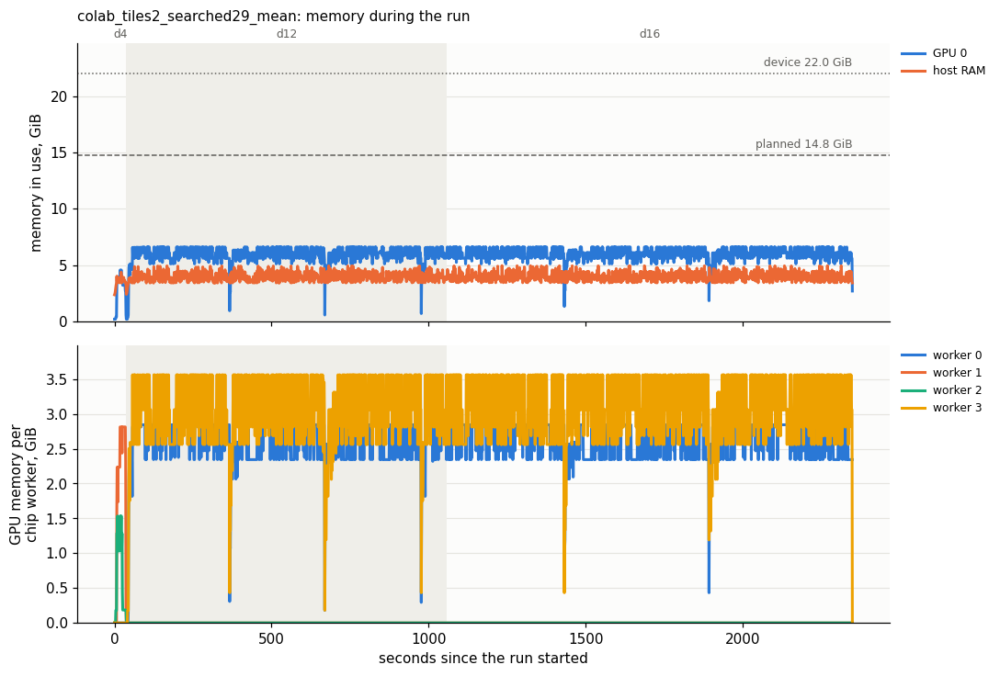

  memory trace         colab_tiles2_searched29_mean.mem.csv, colab_tiles2_searched29_mean.mem.png (2250 samples)
  records              colab_tiles2_searched29_mean.jsonl

Tile benchmark: 4 tile(s), stored layout: 520 qubits, 4 chip(s), loom ghost, ghost max width 27, 33 links, planned 16.30 GiB on 1 GPU(s), 4 chip(s) per GPU
  depths x instances: d4 x 1, d8 x 1, d12 x 3, d16 x 3

$ python3 nighthawk_qrack.py field run --repo rcs-nighthawk --device r3t --family hamming --protocol nnqab --fold 1 --depths 4 8 --instances 1 --out colab_tiles4_stored27_ghost.jsonl --loom ghost --ace-gpu --gpus 0 --chips-per-gpu 4 --vram-gb 22.03 --gtt 0 --no-ace-error-detection --ghost-max-width 27
# --protocol nnqab: single-qubit ensemble set to nnqab (as nn_qab.py)
# cloverfield field-305413ca: 4 chips ['nighthawk120t', 'nighthawk140', 'nighthawk120t', 'nighthawk140'] (2x2), 520 qubits, 33 links (13 facing pairs skipped: no common free colour, or no ghost room under the caps), loom ghost, backend ace, th

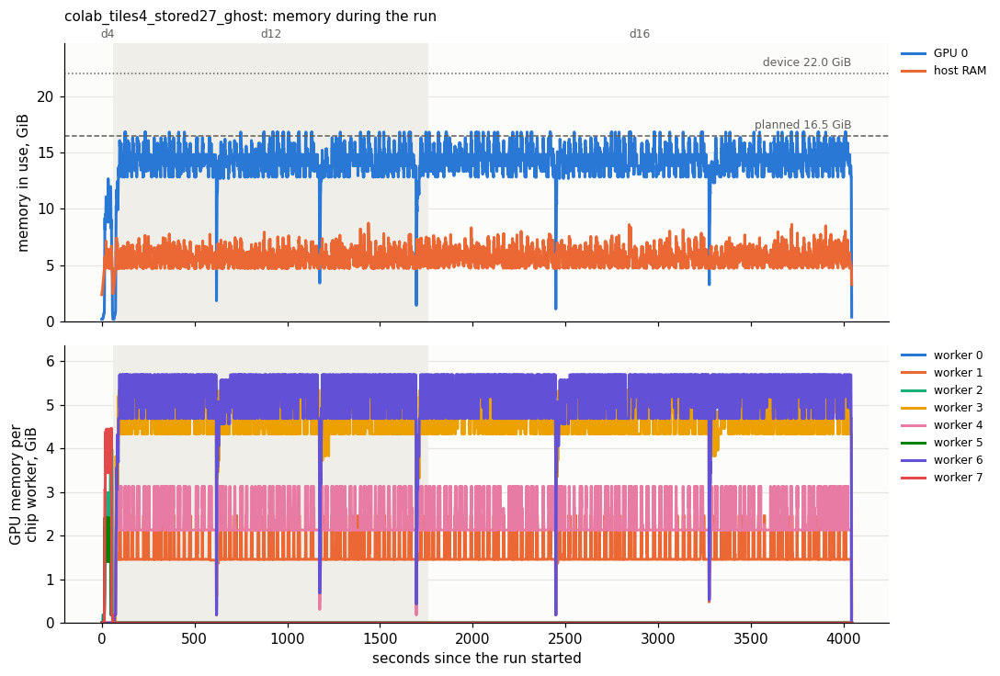

  memory trace         colab_tiles4_stored27_ghost.mem.csv, colab_tiles4_stored27_ghost.mem.png (3866 samples)
  records              colab_tiles4_stored27_ghost.jsonl

=== Tile scaling (Hamming signal, mean +/- se over instances) ===
  tiles qubits   layout  cap   loom     W links              d4              d8             d12             d16   wall s  GPU GiB host GiB  planned
      1    120 searched   30   mean     -     0    0.8345 +/- 0    0.3432 +/- 0 0.1102 +/- 0.034 0.0359 +/- 0.0067   4292.1     4.88     2.59     5.50
      2    260 searched   29   mean     -    10    0.8482 +/- 0 0.3865 +/- 0.024 0.1041 +/- 0.0093 0.0241 +/- 0.0092   2350.4     6.41     2.59    14.60
      4    520   stored   27  ghost    27    33    0.8543 +/- 0 0.3684 +/- 0.02 0.1020 +/- 0.0089 0.0159 +/- 0.002   4043.7    16.62     6.36    16.30

=== Mean-loom fallback (Hamming signal at the comparison depth) ===
  tiles   d inst  cap               stored (loom, links)          searched, mean loom (links)

In [11]:
import json
import math
import re

# Nighthawk r3 tile scaling: the 20 x 26 chip as 1, 2 and 4 loom-woven tiles, each sized for this machine,
# with the tiles' own patch layouts searched for this machine's memory before each tile count runs
RUN_TILE_BENCH = True          # set False to skip
TILE_DEPTHS = MAX_RUN_DEPTHS                    # defaults follow section 5.1; set lists / dicts here to differ
TILE_INSTANCES = MAX_RUN_INSTANCES
TILE_DEPTH_INSTANCES = MAX_RUN_DEPTH_INSTANCES
TILE_TIMEOUT_S = MAX_RUN_TIMEOUT_S

# layout search (nighthawk_qrack.py layoutsearch --lattice) before each tile count
RUN_LAYOUT_SEARCH = True       # False: run the stored tiles (nighthawk120t, nighthawk140) only
LAYOUT_CPSAT_TIME = 300        # seconds per CP-SAT solve (a solve that is not proven optimal uses all of it)
LAYOUT_CANDIDATES = 2          # distinct layouts per geometry
LAYOUT_AUTO_GEOMETRIES = 1     # auto ACE geometries tried besides the tiles' own 184-site register
LAYOUT_EXTRA_SITES = 80        # auto geometries of n .. n + this many sites
LAYOUT_MAX_WIDE = 2            # patches allowed at the cap (the stored tiles use 2)
LAYOUT_MAX_WIDTH = None        # None: the widest cap this machine's share per tile allows; or a number
LAYOUT_MAX_ATTEMPTS = 2        # caps tried per tile count, from the widest down, until the field fits
LAYOUT_OBJECTIVES = ["bcz,seam,couplers", "seam,bcz,couplers"]  # one search round each (fewest couplers through
                                                               # a boundary; fewest boundary qubits)
LAYOUT_TEST_DEPTHS = ["4", "8"]  # Hamming-signal test that ranks candidates and the stored tile ([]: CP-SAT score)
LAYOUT_TEST_INSTANCES = 2      # circuit instances per test depth
LAYOUT_DIR = Path("tile_layouts").resolve()

# mean-loom fallback: searched tiles that place fewer inter-tile links on the ghost loom than the stored tiles
# also run with the mean-field loom (every inter-tile coupler kept, as a mean field), and the two are measured
RUN_MEAN_FALLBACK = True       # False: such tiles step down to the next cap, as before
COMPARE_DEPTH = "8"            # Hamming-signal depth of the comparison (the cut load separates them by d8)
COMPARE_INSTANCES = 3          # circuit instances of each side

# the tiles of nighthawk_qrack.py's r3t preset: their lattices and stored layouts (caps 27 x 2)
TILE_TYPES = {
    "120": dict(n=120, lattice="10x12", preset="nighthawk120t", cap=27),
    "140": dict(n=140, lattice="10x14", preset="nighthawk140", cap=27),
}
STORED_PRESETS = {4: "r3t"}   # stored tiles as a preset of nighthawk_qrack.py: same arguments as section 5.1
TILE_LAYOUTS = {   # tile count -> tile types, grid, links
    1: (["120"], "1x1", "0"),
    2: (["120", "140"], "1x2", "all"),
    4: (["120", "140", "120", "140"], "2x2", "all"),
}


def tile_field(k: int, regs: dict) -> list:
    """field arguments of the k-tile chip with these registers per tile type."""
    types, arr, links = TILE_LAYOUTS[k]
    return ["--chips", ",".join(regs[t] for t in types), "--arrangement", arr, "--links", links]


def tile_share_gib(cfg: dict, k: int) -> float:
    """Memory one tile may use on this machine: its device's VRAM less a reserve per worker, split between the
    tiles placed on that device (as field_base_args places them), or the host budget split between the tiles;
    both times PLAN_SCALE."""
    if cfg["stack"] == "opencl-gpu":
        _, cpg = field_base_args(cfg, k)
        return (plan_vram_gib(cfg) - 0.5 * cpg) / cpg
    return plan_host_gib(cfg) / k


def tile_cap(cfg: dict, k: int) -> int:
    """Widest patch cap for one tile's share. layoutsearch caps count the error-detection ancilla, which the runs
    do not allocate (--no-ace-error-detection), so the simulator at cap w is w - 1 + ED_ANCILLA qubits wide: within
    the max single allocation (single_max_width), and within a third of the share on a GPU (Qrack's 3x rule),
    within half of it on the CPU (with the compose transient). The planner checks the actual layout afterwards."""
    share = tile_share_gib(cfg, k)
    rule = 3.0 if cfg["stack"] == "opencl-gpu" else 2.0
    narrow_by = 1 - ED_ANCILLA
    w = cfg["single_max_width"] + narrow_by
    while w > 1 and rule * cfg["amp_bytes"] * 2 ** (w - narrow_by) / 2 ** 30 > share:
        w -= 1
    return min(w, LAYOUT_MAX_WIDTH) if LAYOUT_MAX_WIDTH else w


def register_stats(names: list) -> dict:
    """verify_register for these registers in a fresh process (saved ones from $NIGHTHAWK_REGISTERS):
    boundary qubits, couplers through a boundary, widths."""
    code = ("import json, sys; sys.argv = ['x']; import nighthawk_qrack as nq; nq.load_register_files(); "
            "print('REGSTATS ' + json.dumps({n: {k: v for k, v in nq.verify_register(n, nq.REGISTERS[n]).items() "
            "if k in ('ok', 'seam', 'replica', 'couplers', 'widths')} for n in " + json.dumps(names) + "}), flush=True)")
    # no OpenCL in this process (it simulates nothing); the result is the line tagged REGSTATS, whatever Qrack prints
    env = dict(os.environ, OCL_ICD_VENDORS="/tmp/no-icd", OCL_ICD_FILENAMES="")
    os.makedirs("/tmp/no-icd", exist_ok=True)
    res = subprocess.run(["python3", "-c", code], capture_output=True, text=True, env=env)
    for line in reversed((res.stdout + "\n" + res.stderr).splitlines()):
        if line.startswith("REGSTATS "):
            try:
                return json.loads(line[len("REGSTATS "):])
            except ValueError:
                break
    print(f"  (register check failed, exit {res.returncode}: {(res.stderr or res.stdout).strip()[-300:]})")
    return {}


def use_register_file(path: Path):
    """Make a search's registers.json visible to field plan / run and their chip workers."""
    cur = [p for p in os.environ.get("NIGHTHAWK_REGISTERS", "").split(os.pathsep) if p]
    if str(path) not in cur:
        os.environ["NIGHTHAWK_REGISTERS"] = os.pathsep.join(cur + [str(path)])


def search_tile(tile: str, w: int, n_wide: int):
    """Best layout of one tile type at cap w x n_wide: one nighthawk_qrack.py layoutsearch round per objective on
    the tile's own lattice, warm-started from the stored tile. Every round ranks its candidates together with the
    best so far (the stored tile in the first round) by the benchmark's Hamming signal, so a searched layout
    replaces the stored one only by measuring better. Cached in LAYOUT_DIR per tile, cap and search settings.
    Returns the register name (the stored tile's name when it stays best) or None."""
    t = TILE_TYPES[tile]
    settings = dict(n=t["n"], lattice=t["lattice"], w=w, n_wide=n_wide, cpsat=LAYOUT_CPSAT_TIME,
                    candidates=LAYOUT_CANDIDATES, auto=LAYOUT_AUTO_GEOMETRIES, extra=LAYOUT_EXTRA_SITES,
                    objectives=list(LAYOUT_OBJECTIVES), test=list(LAYOUT_TEST_DEPTHS),
                    instances=LAYOUT_TEST_INSTANCES, stack=PATCH_CONFIG["stack"],
                    plan_scale=PATCH_CONFIG.get("plan_scale", 1.0))
    tdir = LAYOUT_DIR / f"tile{tile}_w{w}n{n_wide}"
    done = tdir / "done.json"
    try:
        prev = json.loads(done.read_text())
        if prev.get("settings") == settings:
            for f in prev.get("files", []):
                use_register_file(Path(f))
            print(f"  tile {tile} at cap {w}x{n_wide}: cached search, best {prev['best']}")
            return prev["best"]
    except (OSError, ValueError):
        pass
    n_geo = 1 + LAYOUT_AUTO_GEOMETRIES
    per_round = n_geo * LAYOUT_CANDIDATES * LAYOUT_CPSAT_TIME
    print(f"\n  tile {tile} ({t['lattice']}, {t['n']} qubits) at cap {w}x{n_wide}: {len(LAYOUT_OBJECTIVES)} round(s) "
          f"of up to {n_geo} geometries x {LAYOUT_CANDIDATES} candidates x {LAYOUT_CPSAT_TIME} s of CP-SAT "
          f"(at most {len(LAYOUT_OBJECTIVES) * per_round / 60:.0f} min; geometries that cannot hold the tile take "
          f"seconds)" + (f", each ranked against the best so far by the Hamming signal at depths "
                         f"{', '.join(LAYOUT_TEST_DEPTHS)} ({LAYOUT_TEST_INSTANCES} instance(s))" if LAYOUT_TEST_DEPTHS else ""))
    best, files = t["preset"], []
    for i, obj in enumerate(LAYOUT_OBJECTIVES):
        outdir = tdir / f"round{i}"
        cmd = ["python3", "nighthawk_qrack.py", "layoutsearch", "--repo", "rcs-nighthawk",
               "--n", str(t["n"]), "--lattice", t["lattice"],
               "--geometries", "184:2:7", *(["auto"] if LAYOUT_AUTO_GEOMETRIES else []),
               "--max-geometries", str(LAYOUT_AUTO_GEOMETRIES), "--extra-sites", str(LAYOUT_EXTRA_SITES),
               "--max-width", str(w), "--max-wide", str(n_wide), "--objective", obj,
               "--hint", t["preset"], "--compare", best,
               "--candidates", str(LAYOUT_CANDIDATES), "--cpsat-time", str(LAYOUT_CPSAT_TIME),
               "--test-depths", *LAYOUT_TEST_DEPTHS, "--test-family", "hamming", "--test-protocol", "nnqab",
               "--test-no-ace-error-detection", "--test-instances", str(LAYOUT_TEST_INSTANCES), "--test-jobs", "1",
               "--outdir", str(outdir), "--prefix", f"t{tile}w{w}n{n_wide}r{i}"]
        if PATCH_CONFIG["stack"] != "opencl-gpu":
            cmd.append("--cpu")
        print(f"\n  round {i}: objective {obj}, against {best}")
        try:
            r = run_logged(cmd)
        except subprocess.CalledProcessError as e:
            print(f"  round {i}: no verified layout ({str(e.output).strip().splitlines()[-1:]}); best stays {best}")
            continue
        m = re.search(r"^best: (\S+)", r["out"], re.M)
        if m:
            use_register_file(outdir / "registers.json")
            files.append(str(outdir / "registers.json"))
            best = m.group(1)
    tdir.mkdir(parents=True, exist_ok=True)
    done.write_text(json.dumps(dict(settings=settings, best=best, files=files)))
    print(f"  tile {tile} at cap {w}x{n_wide}: best {best}" + (" (the stored tile)" if best == t["preset"] else ""))
    return best


def tile_out_file(k: int, d: dict) -> str:
    """The .jsonl of a k-tile field: section 5.1's when it ran the same field with the same arguments (its points
    are reused, not rerun), else one per layout, cap and loom. The comparison and the benchmark share it, so
    the comparison's points count toward the benchmark."""
    spec = globals().get("MAX_RUN_SPEC")
    if spec and spec["field_args"] == d["field_args"] and spec["run_args"] == d["run_args"]:
        return spec["out_file"]
    return f"colab_tiles{k}_{d['layout']}{d['cap'] or 27}_{d['loom']}.jsonl"


def compare_signal(k: int, d: dict):
    """Hamming signal of field d at COMPARE_DEPTH (COMPARE_INSTANCES instances, nnqab, no error detection):
    (mean, se) as floats, or None when the run fails. Resumes from and adds to the field's .jsonl."""
    cmd = ["python3", "nighthawk_qrack.py", "field", "run", "--repo", "rcs-nighthawk", *d["field_args"],
           "--family", "hamming", "--protocol", "nnqab", "--fold", "1", "--depths", COMPARE_DEPTH,
           "--instances", str(COMPARE_INSTANCES), "--out", tile_out_file(k, d), *d["run_args"]]
    try:
        r = run_logged(cmd, timeout=TILE_TIMEOUT_S)
    except subprocess.CalledProcessError:
        return None
    row = parse_hamming_table(r["out"]).get(int(COMPARE_DEPTH))
    try:
        return float(row["signal"]), float(row["se"])
    except (TypeError, ValueError, KeyError):
        return None


def size_tiles(k: int) -> dict:
    """The k-tile field for this machine: the stored tiles as the baseline, then searched tiles at the widest
    cap one tile's share allows, stepping the cap down until the field fits and (2 and 4 tiles) keeps at least
    the baseline's inter-tile links. Searched tiles that fit but place fewer links on the ghost loom are also
    planned on the mean-field loom (every inter-tile coupler kept), and that field is measured against the
    stored tiles at COMPARE_DEPTH: the higher signal is used. Returns size_field's result with the layout it used
    and the comparison, if one ran."""
    preset = {t: TILE_TYPES[t]["preset"] for t in TILE_TYPES}
    base = size_field(PATCH_CONFIG, STORED_PRESETS.get(k) or tile_field(k, preset), k)
    base.update(layout="stored", regs=preset, cap=None, compare=None)
    if not RUN_LAYOUT_SEARCH:
        return base
    w0 = tile_cap(PATCH_CONFIG, k)
    floor = max(TILE_TYPES[t]["cap"] for t in TILE_LAYOUTS[k][0])
    print(f"\n{k} tile(s): {tile_share_gib(PATCH_CONFIG, k):.2f} GiB per tile -> patch cap {w0} "
          f"(simulators {w0 - 1 + ED_ANCILLA} qubits, no error-detection ancilla)"
          + ("" if w0 > floor else f", not above the stored tiles' {floor}: stored tiles kept"))
    base_sig = None
    for w in range(w0, floor, -1)[:LAYOUT_MAX_ATTEMPTS]:
        regs = {t: search_tile(t, w, LAYOUT_MAX_WIDE) for t in sorted(set(TILE_LAYOUTS[k][0]))}
        if any(v is None for v in regs.values()):
            continue
        if all(regs[t] == preset[t] for t in regs):
            print(f"  cap {w}: the stored tiles measured best: kept")
            return base
        d = size_field(PATCH_CONFIG, tile_field(k, regs), k)
        d.update(layout="searched", regs=regs, cap=w, compare=None)
        keeps_links = k == 1 or d["links"] >= base["links"]
        print(f"  cap {w}: {'fits' if d['runnable'] else 'does not fit'}, loom {d['loom'] or '-'}, "
              f"{d['links']} links (stored tiles: {base['links']})"
              + ("" if keeps_links or not d["runnable"] else ": fewer inter-tile links"))
        if d["runnable"] and keeps_links:
            return d
        if not (d["runnable"] and RUN_MEAN_FALLBACK and base["runnable"]):
            continue
        # every inter-tile coupler on the mean-field loom, measured against the stored tiles' ghost field
        m = size_field(PATCH_CONFIG, tile_field(k, regs), k, mean_only=True)
        m.update(layout="searched", regs=regs, cap=w, compare=None)
        if not m["runnable"]:
            print(f"  cap {w}: the mean-field loom does not fit either: next cap")
            continue
        print(f"  cap {w}: comparing at d{COMPARE_DEPTH} ({COMPARE_INSTANCES} instances): searched tiles on the "
              f"mean-field loom ({m['links']} links) against the stored tiles on the {base['loom']} loom "
              f"({base['links']} links)")
        if base_sig is None:
            base_sig = compare_signal(k, base)
        m_sig = compare_signal(k, m)
        cmp_ = dict(depth=int(COMPARE_DEPTH), instances=COMPARE_INSTANCES, stored=base_sig, searched_mean=m_sig,
                    stored_loom=base["loom"], stored_links=base["links"], mean_links=m["links"], cap=w)
        fmt = lambda x: f"{x[0]:.4f} +/- {x[1]:.4f}" if x else "failed"
        won = m_sig is not None and (base_sig is None or m_sig[0] > base_sig[0])
        print(f"  d{COMPARE_DEPTH}: stored tiles ({base['loom']}) {fmt(base_sig)}, searched tiles (mean) {fmt(m_sig)}"
              f": {'searched tiles on the mean-field loom used' if won else 'stored tiles kept'}")
        base["compare"] = cmp_
        if won:
            m["compare"] = cmp_
            return m
    print(f"  {k} tile(s): stored tiles kept")
    return base


if not RUN_TILE_BENCH:
    print("RUN_TILE_BENCH is False: skipped")
else:
    print(f"Sizing each tile count for this machine ({PATCH_CONFIG['budget_summary']})...")
    TILE_SIZING = {k: size_tiles(k) for k in sorted(TILE_LAYOUTS)}

    # layouts used, against the stored tiles (boundary qubits = seam, couplers through a boundary = replica)
    names = sorted({r for d in TILE_SIZING.values() for r in d["regs"].values()}
                   | {t["preset"] for t in TILE_TYPES.values()})
    stats = register_stats(names)
    print(f"\n  {'register':24s} {'tile':>4s} {'boundary q':>10s} {'bnd couplers':>12s}  widths (counted with the ancilla "
          f"the runs leave out)")
    for nm in names:
        s_ = stats.get(nm, {})
        tile = next((t for t, v in TILE_TYPES.items() if v["preset"] == nm or nm.startswith(f"t{t}w")), "?")
        print(f"  {nm:24s} {tile:>4s} {s_.get('seam', '?'):>10} {str(s_.get('replica', '?')) + '/' + str(s_.get('couplers', '?')):>12s}  "
              f"{s_.get('widths', '?')}")

    print(f"\n  {'tiles':>5s} {'qubits':>6s} {'layout':>8s} {'cap':>4s} {'chips/GPU' if gpu else 'where':>9s} "
          f"{'loom':>6s} {'ghost W':>7s} {'links':>5s} {'planned GiB':>11s}")
    for k, d in TILE_SIZING.items():
        print(f"  {k:5d} {d['qubits'] or 0:6d} {d['layout']:>8s} {str(d['cap'] or 27):>4s} "
              f"{str(d['chips_per_gpu']) if gpu else 'CPU':>9s} {d['loom'] or '-':>6s} "
              f"{ghost_label(d):>7s} {d['links']:5d} {planned_gib(d):11.2f}"
              + ("" if d["runnable"] else "   does not fit this machine: skipped"))

    TILE_RESULTS = {}
    for k, d in TILE_SIZING.items():
        if not d["runnable"]:
            continue
        print("\n" + "=" * 78)
        out_file = tile_out_file(k, d)
        spec = globals().get("MAX_RUN_SPEC")
        if spec and out_file == spec["out_file"]:
            print(f"{k} tile(s): same field and arguments as section 5.1's run, its records ({out_file}) are reused")
        TILE_RESULTS[k] = bench_field(f"Tile benchmark: {k} tile(s), {d['layout']} layout", d, out_file,
                                      depths=TILE_DEPTHS, instances=TILE_INSTANCES,
                                      depth_instances=TILE_DEPTH_INSTANCES, timeout=TILE_TIMEOUT_S)

    # side-by-side comparison
    deps = sorted({int(x) for x in TILE_DEPTHS})
    print("\n=== Tile scaling (Hamming signal, mean +/- se over instances) ===")
    print(f"  {'tiles':>5s} {'qubits':>6s} {'layout':>8s} {'cap':>4s} {'loom':>6s} {'W':>5s} {'links':>5s} "
          + " ".join(f"{'d' + str(x):>15s}" for x in deps)
          + f" {'wall s':>8s} {'GPU GiB':>8s} {'host GiB':>8s} {'planned':>8s}")
    for k, d in TILE_SIZING.items():
        res = TILE_RESULTS.get(k)
        if res is None:
            print(f"  {k:5d} {d['qubits'] or 0:6d}  not run on this machine")
            continue
        cells = []
        for x in deps:
            w_ = res["rows"].get(x)
            cells.append(f"{w_['signal']} +/- {w_['se']}" if w_ else "-")
        gpu_used = sum(v for kk, v in res["used"].items() if kk != "host")
        print(f"  {k:5d} {d['qubits'] or 0:6d} {d['layout']:>8s} {str(d['cap'] or 27):>4s} {d['loom']:>6s} "
              f"{ghost_label(d):>5s} {d['links']:5d} "
              + " ".join(f"{c:>15s}" for c in cells)
              + f" {res['wall']:8.1f} {gpu_used if gpu else 0:8.2f} {res['used'].get('host', 0):8.2f} "
              f"{planned_gib(d):8.2f}" + ("  FAILED points" if res["failed"] else "")
              + ("  TIMED OUT" if res["timed_out"] else ""))

    # mean-loom fallback comparisons (searched tiles that lost ghost links, against the stored tiles)
    cmps = {k: d["compare"] for k, d in TILE_SIZING.items() if d.get("compare")}
    if cmps:
        fmt = lambda x: f"{x[0]:.4f} +/- {x[1]:.4f}" if x else "failed"
        print("\n=== Mean-loom fallback (Hamming signal at the comparison depth) ===")
        print(f"  {'tiles':>5s} {'d':>3s} {'inst':>4s} {'cap':>4s} {'stored (loom, links)':>34s} "
              f"{'searched, mean loom (links)':>36s}  used")
        for k, c in cmps.items():
            print(f"  {k:5d} {c['depth']:3d} {c['instances']:4d} {c['cap']:4d} "
                  f"{fmt(c['stored']) + ' (' + c['stored_loom'] + ', ' + str(c['stored_links']) + ')':>34s} "
                  f"{fmt(c['searched_mean']) + ' (' + str(c['mean_links']) + ')':>36s}  {TILE_SIZING[k]['layout']}")


### 5.3 Dual Nighthawk r3 (`r3x2t`, 1,040 qubits)

IBM's planned 2027 system, `r3x2`: two 520-qubit r3 chips joined by ten l-couplers. A 520-qubit chip has no single ACE layout (a ring of patches does not hold the 20 x 26 lattice, README 3.13), so the run uses `r3x2t`: each r3 chip as the four `r3t` tiles, eight tiles on a 2 x 4 grid. The loom carries all 46 couplers across each chip's two cuts and the ten l-couplers between the chips, on the rows `r3x2` puts them on (`--pair-links 1-2:0,2,4,6,8;5-6:1,3,5,7,9`). The field has exactly the couplers and l-couplers of `r3x2` (`field selftest` [14] checks it); 102 loom links in all.

Section 5 sizes it like the other fields (ghost cap, links, planned GiB in the table there). The cell runs the woven field and, with `RUN_DUAL_CUT`, the same field with the links cut (same anchors, links left out of the circuit) as the baseline, both with the memory trace. Then come the plan's field map (ACE patches per tile, seams, link anchors, the links the ghost loom placed and the couplers left without one) and the one-page poster of the records.

| Setting | Default | Meaning |
|---|---|---|
| `RUN_DUAL` | `True` | `False` skips the run (the plan's field map is still drawn) |
| `DUAL_DEPTHS` | `["4", "8"]` | depths |
| `DUAL_INSTANCES` | `1` | circuit instances per depth |
| `RUN_DUAL_CUT` | `True` | also run the cut-links baseline |
| `DUAL_TIMEOUT_S` | `14400` | limit per `field run` call |

Records go to `colab_dual_r3x2t.jsonl` (woven and cut in one file; a rerun resumes); graphs to `colab_dual_r3x2t.plan.png` and `colab_dual_r3x2t.poster.png`.


Dual Nighthawk r3 (r3x2t), woven: 1040 qubits, 8 chip(s), loom ghost, ghost max width 26/3, 50 links, planned 17.70 GiB on 1 GPU(s), 8 chip(s) per GPU
  depths x instances: d4 x 1, d8 x 1

$ python3 nighthawk_qrack.py field run --repo rcs-nighthawk --device r3x2t --family hamming --protocol nnqab --fold 1 --depths 4 8 --instances 1 --out colab_dual_r3x2t.jsonl --loom ghost --ace-gpu --gpus 0 --chips-per-gpu 8 --vram-gb 22.03 --gtt 0 --no-ace-error-detection --ghost-max-width 26 --ghost-max-wide 3
# --protocol nnqab: single-qubit ensemble set to nnqab (as nn_qab.py)
# cloverfield field-65501498: 8 chips ['nighthawk120t', 'nighthawk140', 'nighthawk120t', 'nighthawk140', 'nighthawk120t', 'nighthawk140', 'nighthawk120t', 'nighthawk140'] (2x4), 1040 qubits, 50 links (52 facing pairs skipped: no common free colour, or no ghost room under the caps), loom ghost, backend ace, theta nnqab, family hamming, protocol nnqab
# looms: 1 on GPUs 0, 0 on the CPU; 2 points
Device #0, Building JIT.
Device

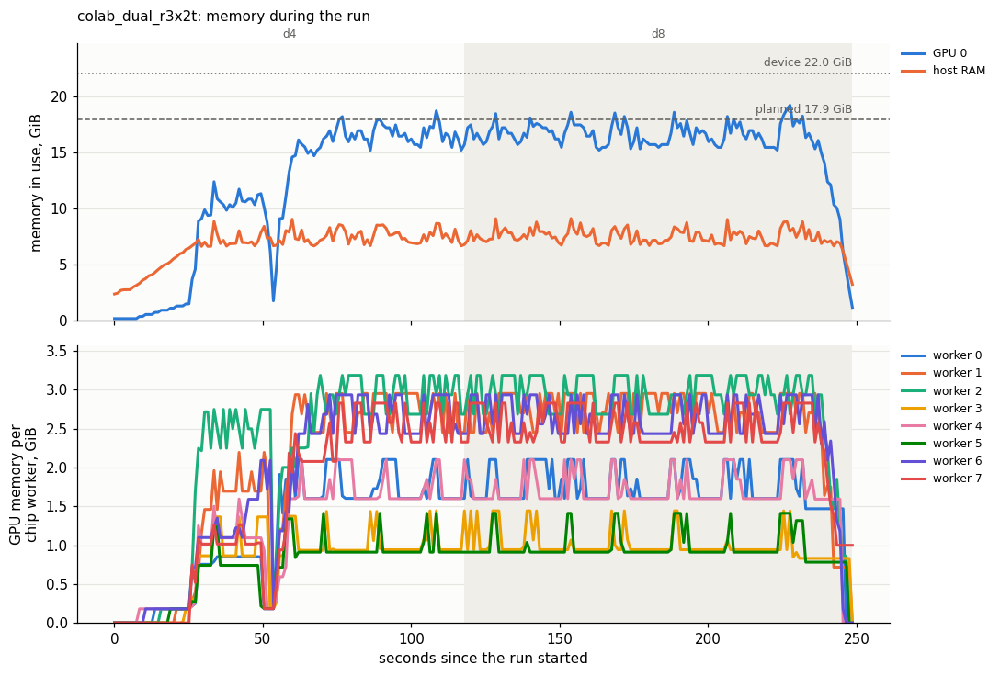

  memory trace         colab_dual_r3x2t.mem.csv, colab_dual_r3x2t.mem.png (237 samples)
  records              colab_dual_r3x2t.jsonl
Dual Nighthawk r3 (r3x2t), links cut: 1040 qubits, 8 chip(s), loom ghost, ghost max width 26/3, 50 links, planned 17.70 GiB on 1 GPU(s), 8 chip(s) per GPU
  depths x instances: d4 x 1, d8 x 1

$ python3 nighthawk_qrack.py field run --repo rcs-nighthawk --device r3x2t --family hamming --protocol nnqab --fold 1 --depths 4 8 --instances 1 --out colab_dual_r3x2t.jsonl --loom ghost --ace-gpu --gpus 0 --chips-per-gpu 8 --vram-gb 22.03 --gtt 0 --no-ace-error-detection --ghost-max-width 26 --ghost-max-wide 3 --cut-links
# --protocol nnqab: single-qubit ensemble set to nnqab (as nn_qab.py)
# cloverfield field-34107eb3: 8 chips ['nighthawk120t', 'nighthawk140', 'nighthawk120t', 'nighthawk140', 'nighthawk120t', 'nighthawk140', 'nighthawk120t', 'nighthawk140'] (2x4), 1040 qubits, 50 links (cut) (52 facing pairs skipped: no common free colour, or no ghost room under 

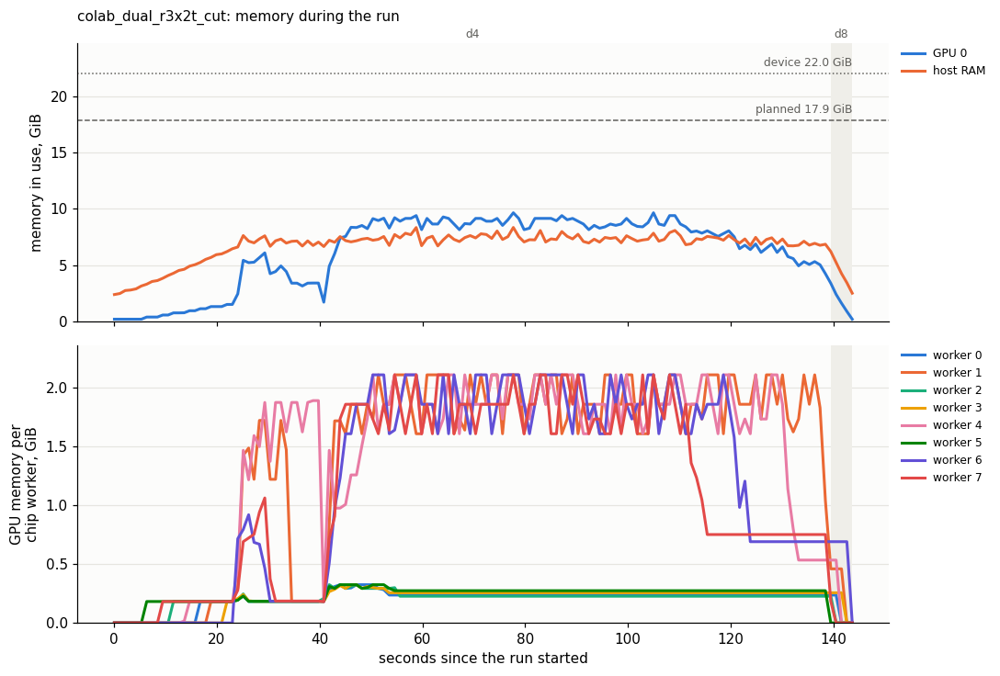

  memory trace         colab_dual_r3x2t_cut.mem.csv, colab_dual_r3x2t_cut.mem.png (138 samples)
  records              colab_dual_r3x2t.jsonl

=== r3x2t: woven against links cut (Hamming signal) ===
    d              woven          links cut      gap
    4       0.8318 +/- 0       0.8392 +/- 0   0.0074
    8       0.3623 +/- 0       0.4187 +/- 0   0.0564
  colab_dual_r3x2t.plan.png


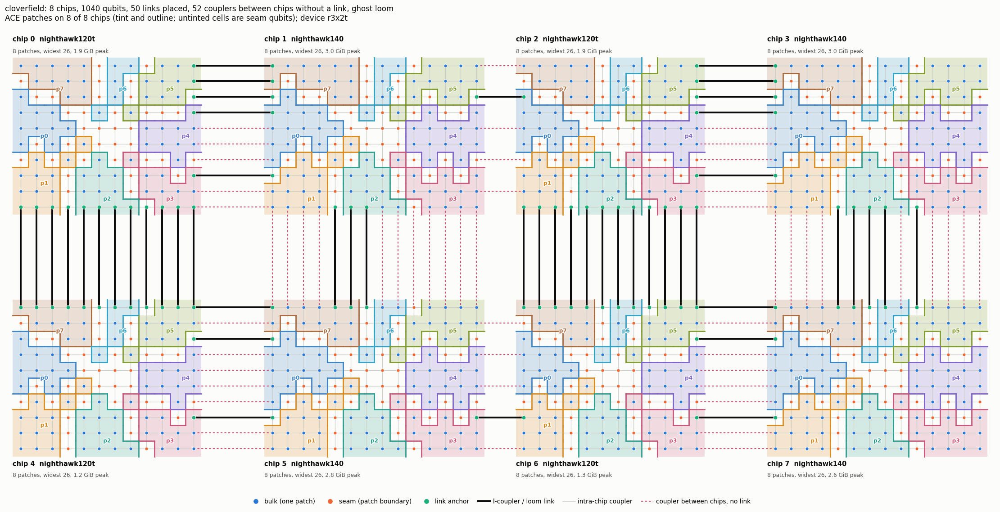

  colab_dual_r3x2t.poster.png


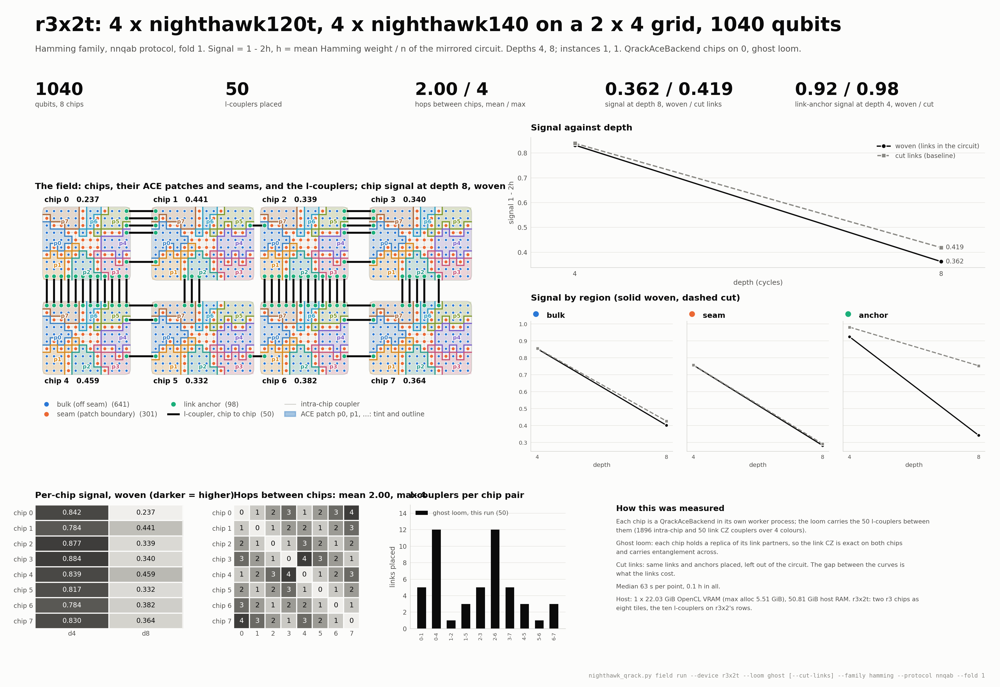

In [12]:
# Dual Nighthawk r3: r3x2 as eight tiles (r3x2t), woven and with the links cut, then its graphs
RUN_DUAL = True
DUAL_DEPTHS = ["4", "8"]
DUAL_INSTANCES = 1
RUN_DUAL_CUT = True            # the cut-links baseline: what the 102 loom links cost or keep
DUAL_TIMEOUT_S = 4 * 3600
DUAL_OUT = "colab_dual_r3x2t.jsonl"

d = PATCH_CONFIG["devices"].get("r3x2t")
if d is None:
    print("r3x2t was not sized (FIELD_DEVICES in section 5): nothing to run")
elif not d["runnable"]:
    print("r3x2t does not fit this host's detected budget with any loom: not run")
    field_graphs(d, DUAL_OUT)
else:
    sides = [("woven", d)]
    if RUN_DUAL_CUT:
        sides.append(("links cut", dict(d, run_args=[*d["run_args"], "--cut-links"])))
    DUAL_RESULT = {}
    if RUN_DUAL:
        for side, dd in sides:
            DUAL_RESULT[side] = bench_field(f"Dual Nighthawk r3 (r3x2t), {side}", dd, DUAL_OUT, depths=DUAL_DEPTHS,
                                            instances=DUAL_INSTANCES, depth_instances={}, timeout=DUAL_TIMEOUT_S,
                                            trace_stem="colab_dual_r3x2t" + ("_cut" if side == "links cut" else ""))
        if len(DUAL_RESULT) == 2:
            w, c = DUAL_RESULT["woven"]["rows"], DUAL_RESULT["links cut"]["rows"]
            print("\n=== r3x2t: woven against links cut (Hamming signal) ===")
            print(f"  {'d':>3s} {'woven':>18s} {'links cut':>18s} {'gap':>8s}")
            for dep in sorted(set(w) & set(c)):
                try:
                    gap = float(c[dep]["signal"]) - float(w[dep]["signal"])
                except (TypeError, ValueError, KeyError):
                    gap = float("nan")
                print(f"  {dep:3d} {w[dep]['signal'] + ' +/- ' + str(w[dep]['se']):>18s} "
                      f"{c[dep]['signal'] + ' +/- ' + str(c[dep]['se']):>18s} {gap:8.4f}")
    else:
        print("RUN_DUAL is False: plan graph only")
    field_graphs(d, DUAL_OUT, note="r3x2t: two r3 chips as eight tiles, the ten l-couplers on r3x2's rows.")


## 6. Execute `nighthawk_graph.py` on Measured Results

Generate summary tables, multi-chip Cloverfield topology posters (`r3_topo.jsonl`), and RCS / Mirror / FXEB / Hamming figures (`../../released/nighthawk/rcs-nighthawk/nighthawk.tar.gz`) using [`nighthawk_graph.py`](https://github.com/twobombs/thereminq-examples/blob/main/devices/announced/nighthawk-r3/nighthawk_graph.py).

### 6.1 Cloverfield (`clover6`, 720 Qubits) Measured Topologies (`r3_topo.jsonl`)

Plot the measured 720-qubit Cloverfield records across `ring`, `hub 1`, and `grid + 0-5,2-3` topologies (view 29, Hamming views 12–13, and one-page topology posters).

field-093ed631: 4 points, field-25da32df: 4 points, field-52dcd722: 4 points, field-650ca988: 4 points, field-6edd8b39: 4 points, field-9128f452: 4 points; hwxeb circuits: 0; shor9 records: 0; ghz records: 0; shor_bridge records: 0; dual_r1 rows: 0; dual_map chains: 0; shor_alg circuits: 0; read 18:47:22
wrote 24 points of 6 configurations to plots_r3/r3_topo.csv
field-093ed631: 4 points, field-25da32df: 4 points, field-52dcd722: 4 points, field-650ca988: 4 points, field-6edd8b39: 4 points, field-9128f452: 4 points; hwxeb circuits: 0; shor9 records: 0; ghz records: 0; shor_bridge records: 0; dual_r1 rows: 0; dual_map chains: 0; shor_alg circuits: 0; read 18:47:23
saved plots_r3/12_hm.png
/content/thereminq-examples/devices/announced/nighthawk-r3/nighthawk_graph.py:1205: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  a1.legend(fontsize=8, ncol=2)
/content/theremin

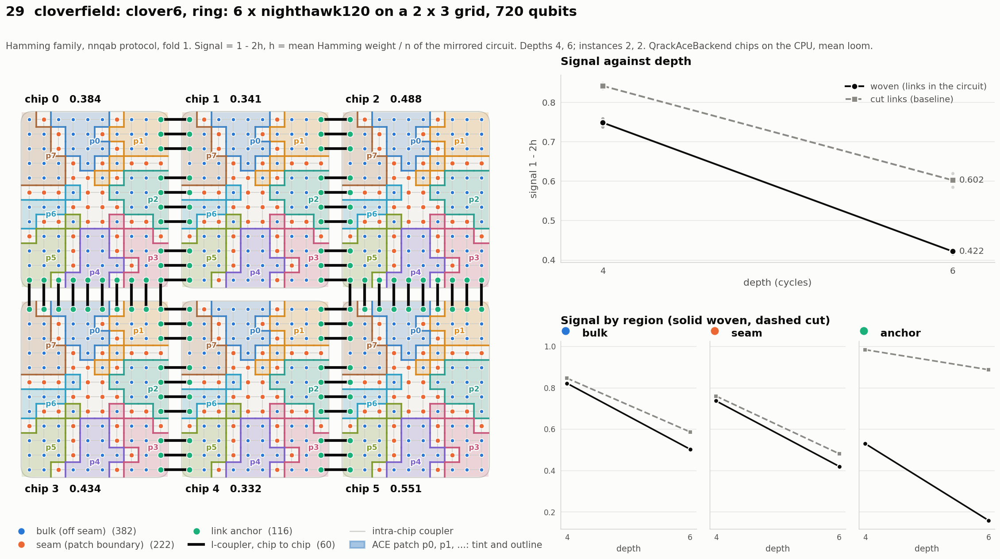

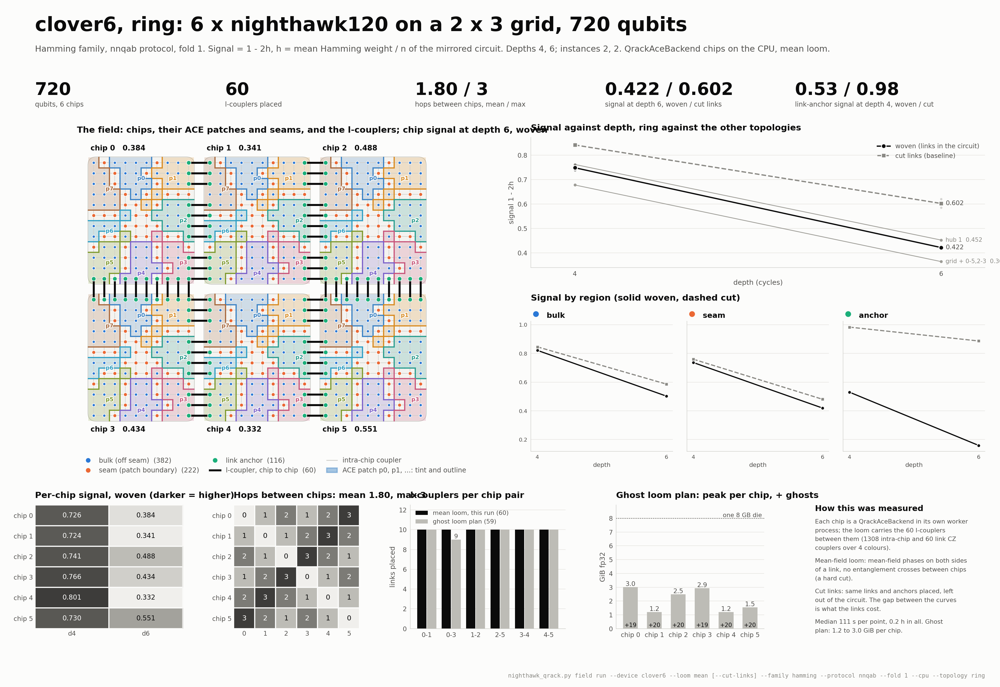

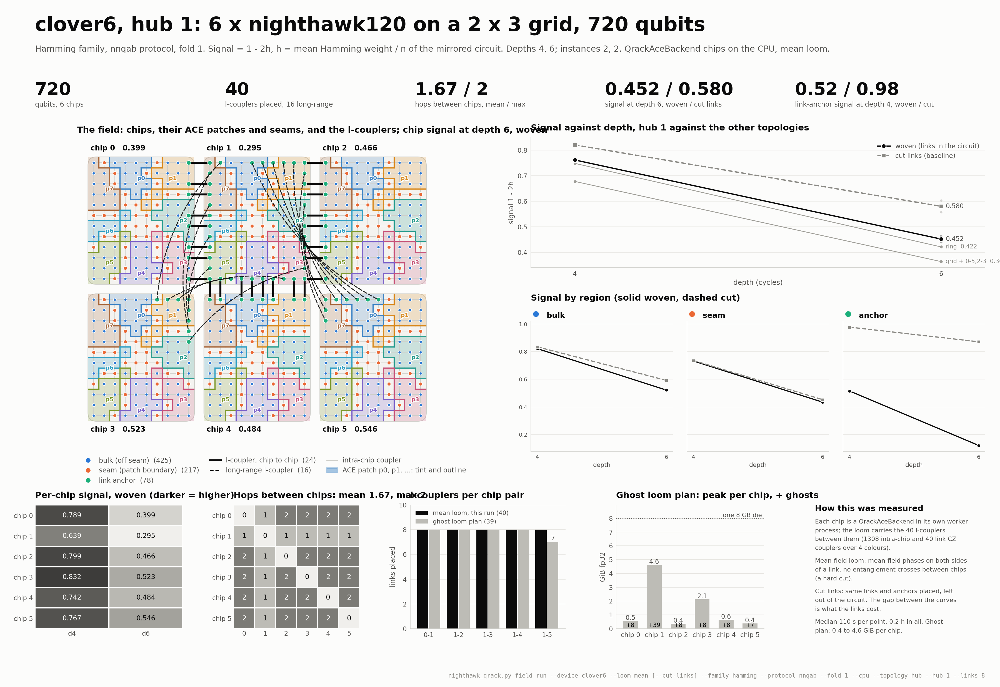

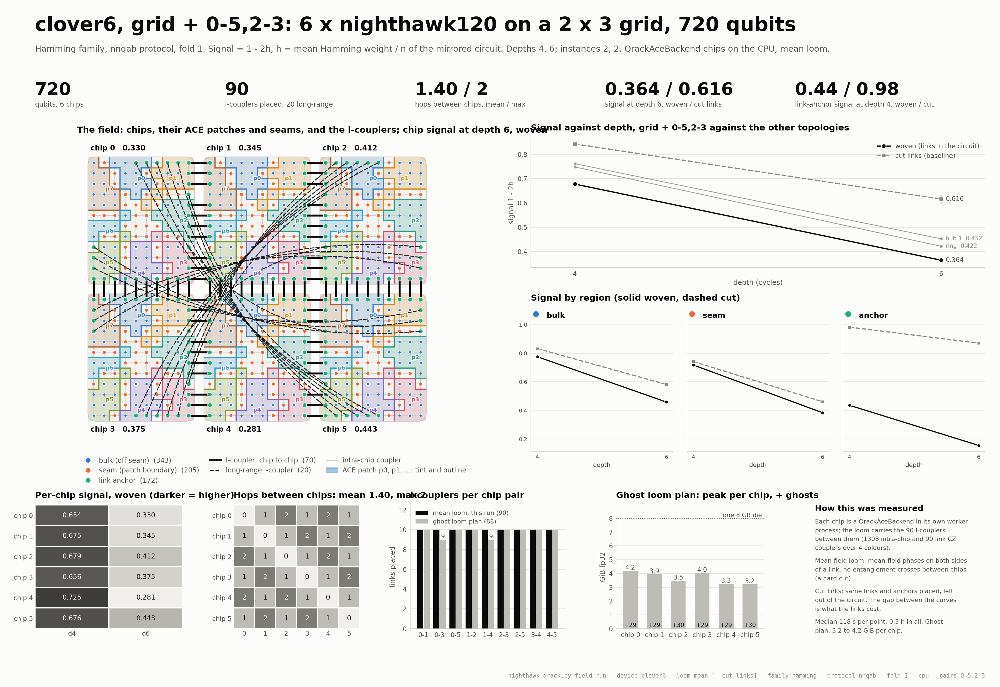

In [13]:
from pathlib import Path
from IPython.display import Image, display

Path("plots_r3").mkdir(exist_ok=True)

!python3 nighthawk_graph.py --out r3_topo.jsonl --table plots_r3/r3_topo.csv
!python3 nighthawk_graph.py --out r3_topo.jsonl --save plots_r3 --figs 12,13,29
!python3 nighthawk_graph.py --out r3_topo.jsonl --poster plots_r3/r3_topo_ring.png --poster-topology ring
!python3 nighthawk_graph.py --out r3_topo.jsonl --poster plots_r3/r3_topo_hub1.png --poster-topology "hub 1"
!python3 nighthawk_graph.py --out r3_topo.jsonl --poster plots_r3/r3_topo_grid_shortcuts.png --poster-topology "grid + 0-5,2-3"

for img_name in [
    "29_fld.png",
    "r3_topo_ring.png",
    "r3_topo_hub1.png",
    "r3_topo_grid_shortcuts.png",
]:
    p = Path("plots_r3") / img_name
    if p.is_file():
        display(Image(filename=str(p)))

### 6.2 Measured RCS, Mirror, Forward XEB, and Hamming Sweeps (`nighthawk.tar.gz`)

Extract the measured sweep archive (`../../released/nighthawk/rcs-nighthawk/nighthawk.tar.gz`, 36 record files / 949 points across 24 configurations) and run `nighthawk_graph.py` to generate the comparison table and views 1–13.

$ python3 /content/thereminq-examples/devices/announced/nighthawk-r3/nighthawk_graph.py --table /content/thereminq-examples/devices/announced/nighthawk-r3/plots_measured/harvest.csv
Device #0, Building JIT.
harvesting 36 record files: big_ace.jsonl, big_tile.jsonl, big_var.jsonl, clean_ace.jsonl, clean_ace_c4r7.jsonl, clean_ace_c7r4.jsonl, clean_ace_seam5.jsonl, clean_ace_seam6.jsonl, clean_ace_seam7.jsonl, clvk_t1.jsonl, dan_hamming_36.jsonl, dan_hamming_40.jsonl, dan_hamming_45.jsonl, dan_hamming_49.jsonl, dan_hamming_53.jsonl, dan_hamming_57.jsonl, dan_hamming_61.jsonl, lay_1_7.jsonl, lay_2_2.jsonl, lay_2_7.jsonl, lay_4_3.jsonl, lay_4_4.jsonl, mirror61_dan_d16.jsonl, mirror61_dan_nnqab_cpu.jsonl, mirror61_dan_prob_clvk.jsonl, mirror61_dan_prob_cpu.jsonl, mirror61_dan_prob_pocl.jsonl, mirror61r2_haar.jsonl, pocl_d8_cap.jsonl, pocl_d8_debug.jsonl, repro_d12_cpu.jsonl, tile_1_7.jsonl, tile_2_2.jsonl, tile_2_7.jsonl, tile_4_3.jsonl, tile_4_4.jsonl
ace-01b20966: 149 points, ace-065b88fb:

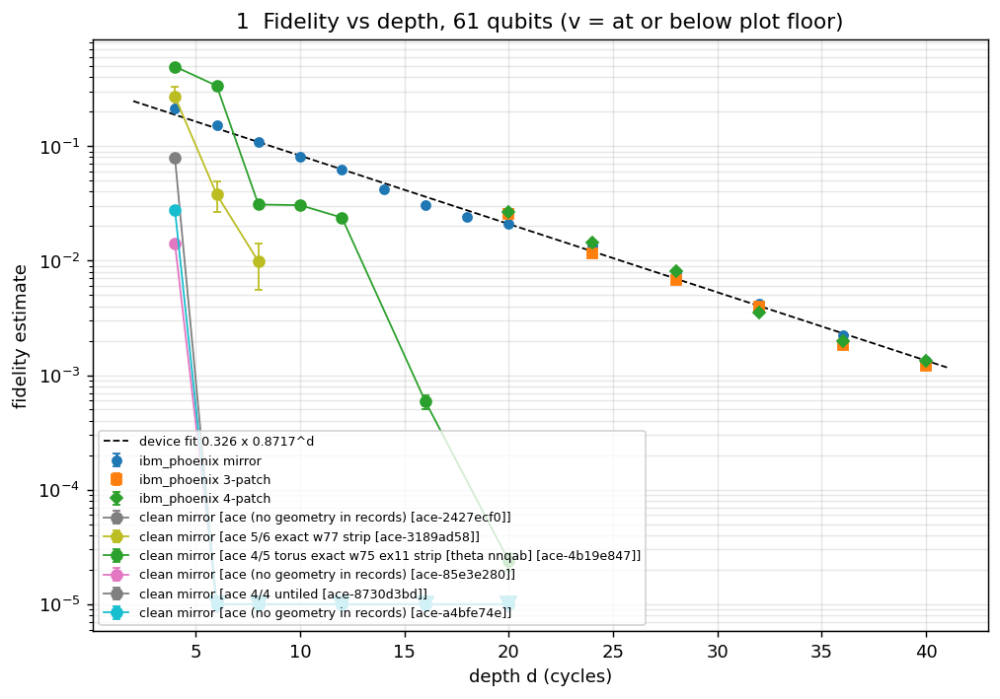


=== 2_sweep.png ===


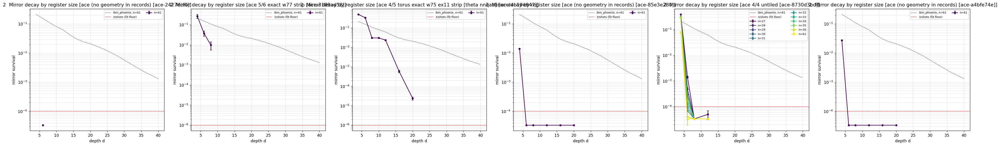


=== 3_bN.png ===


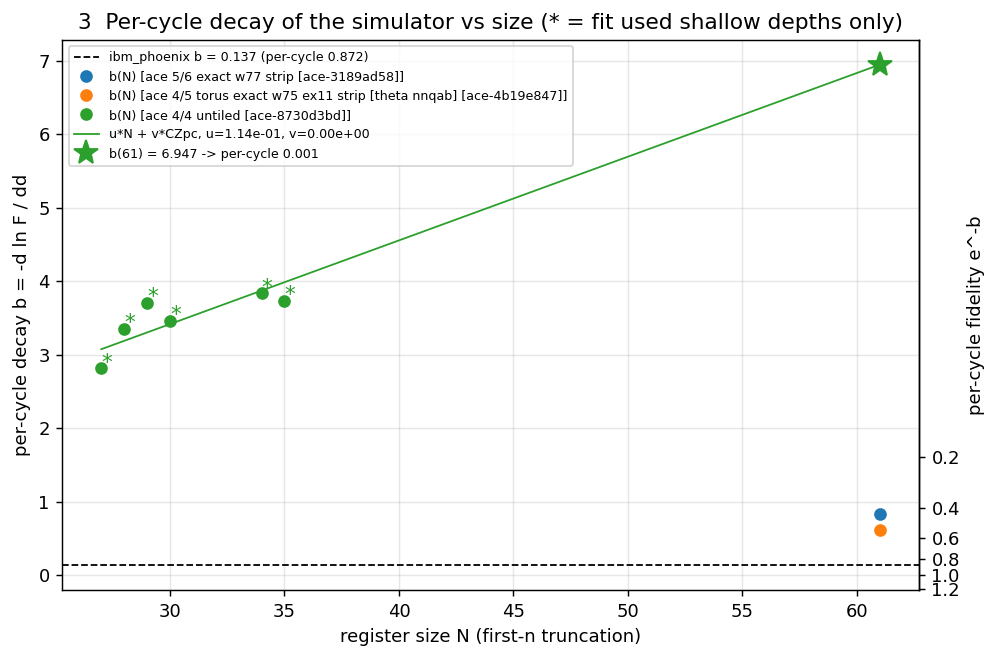


=== 4_mbits_ace-2427ecf0.png ===


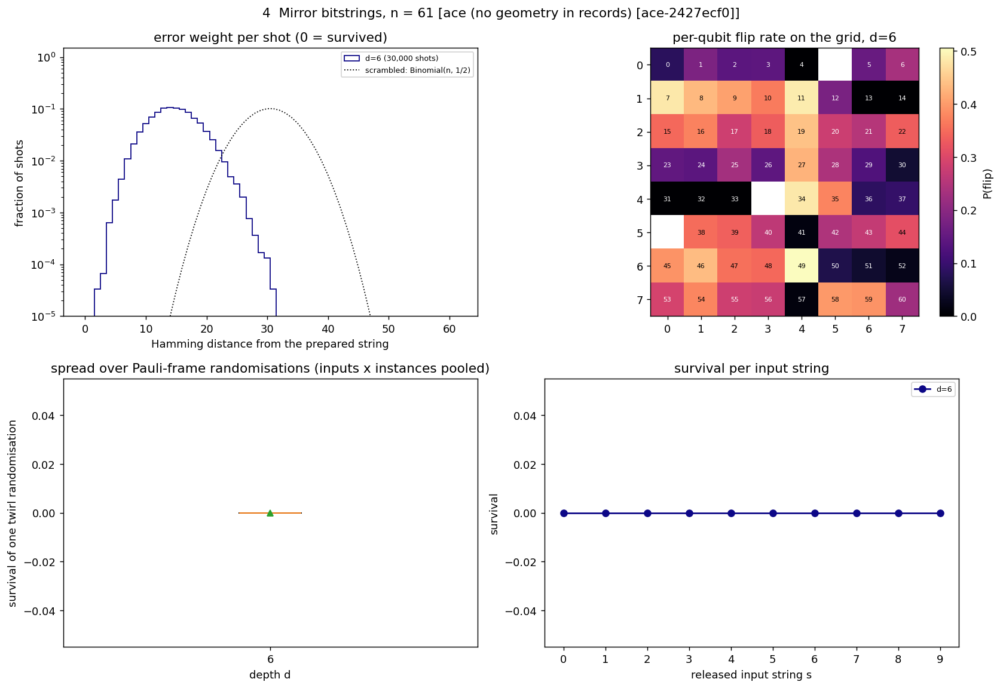


=== 4_mbits_ace-85e3e280.png ===


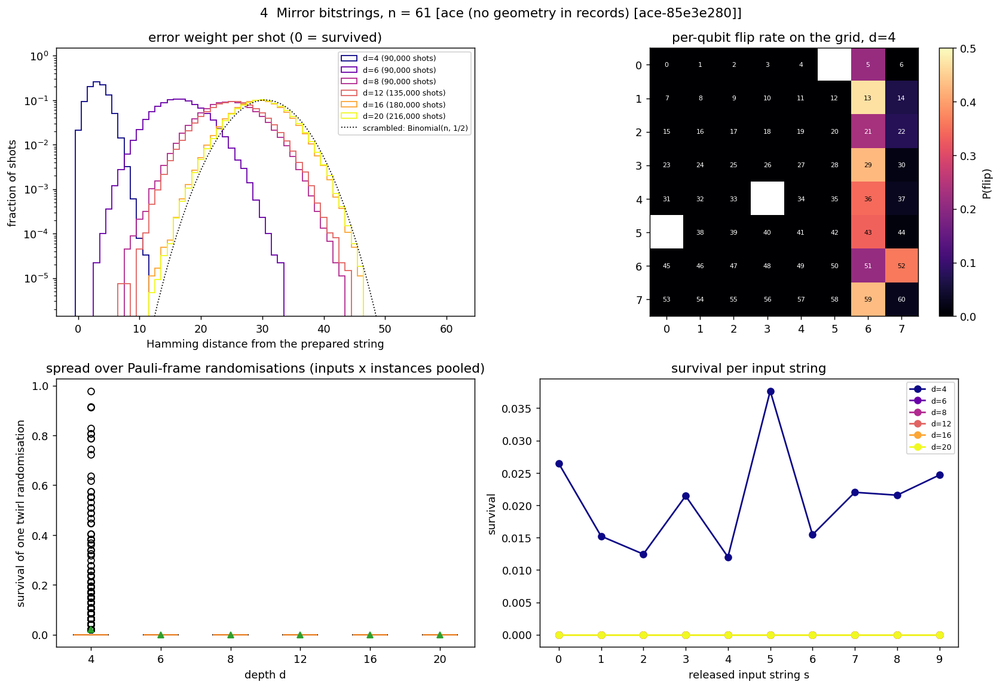


=== 4_mbits_ace-a4bfe74e.png ===


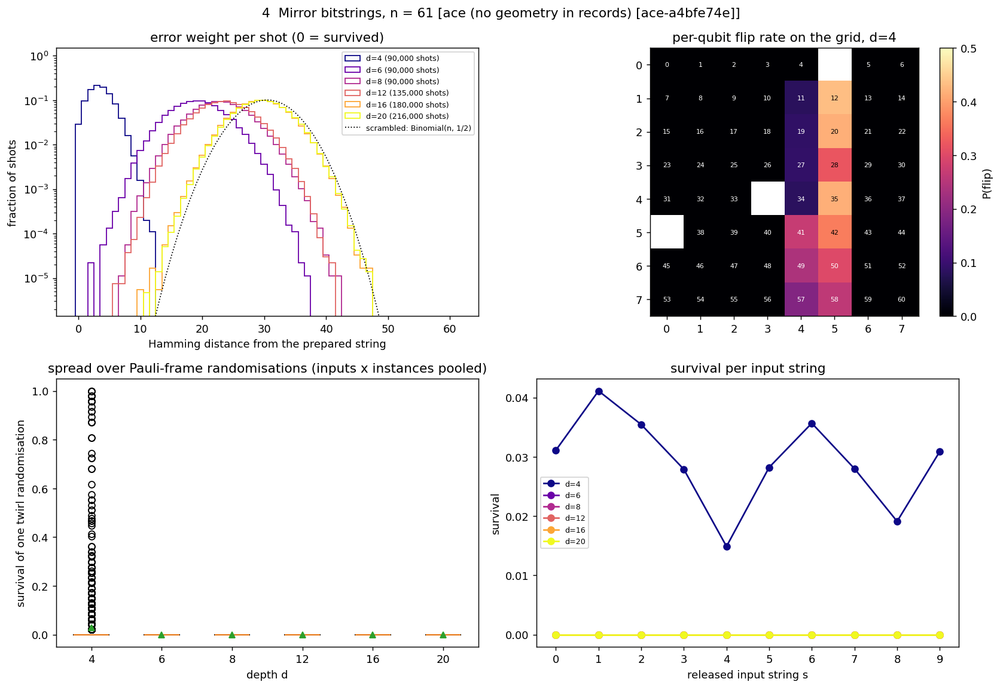


=== 6_release.png ===


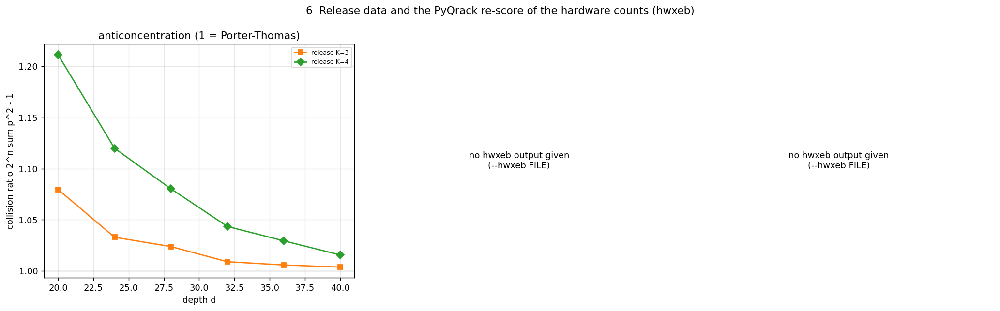


=== 7_cost.png ===


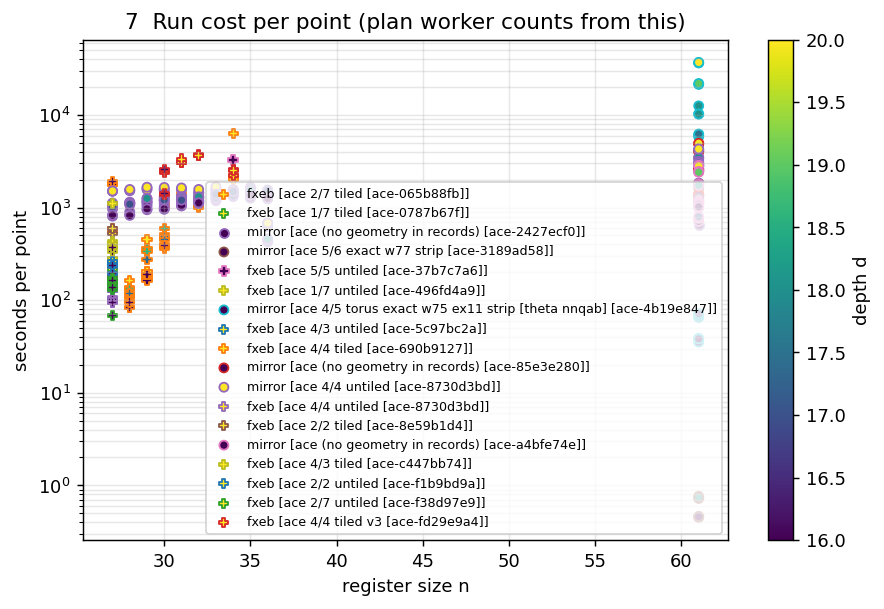


=== 8_fxd.png ===


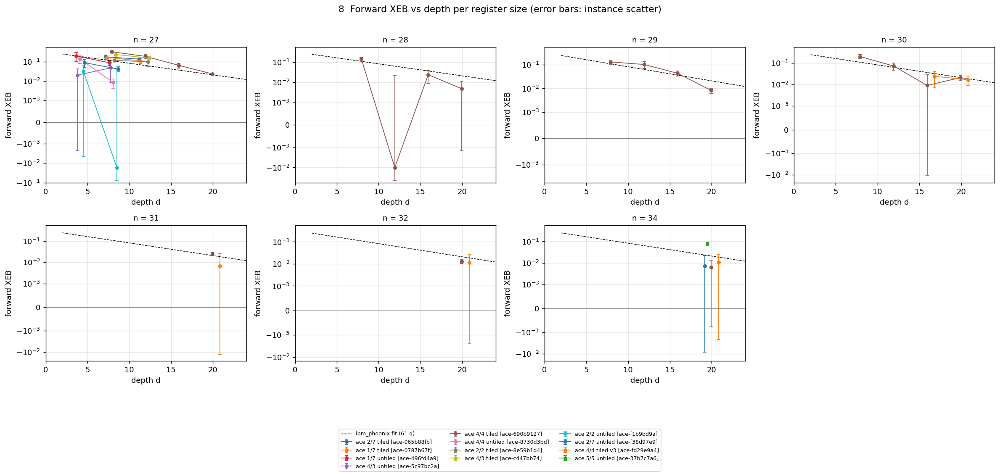


=== 9_fxn.png ===


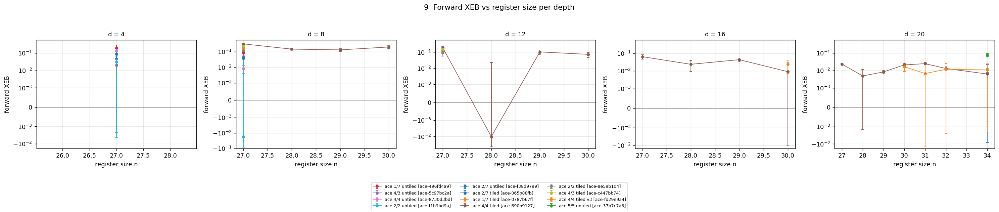


=== 10_fxb.png ===


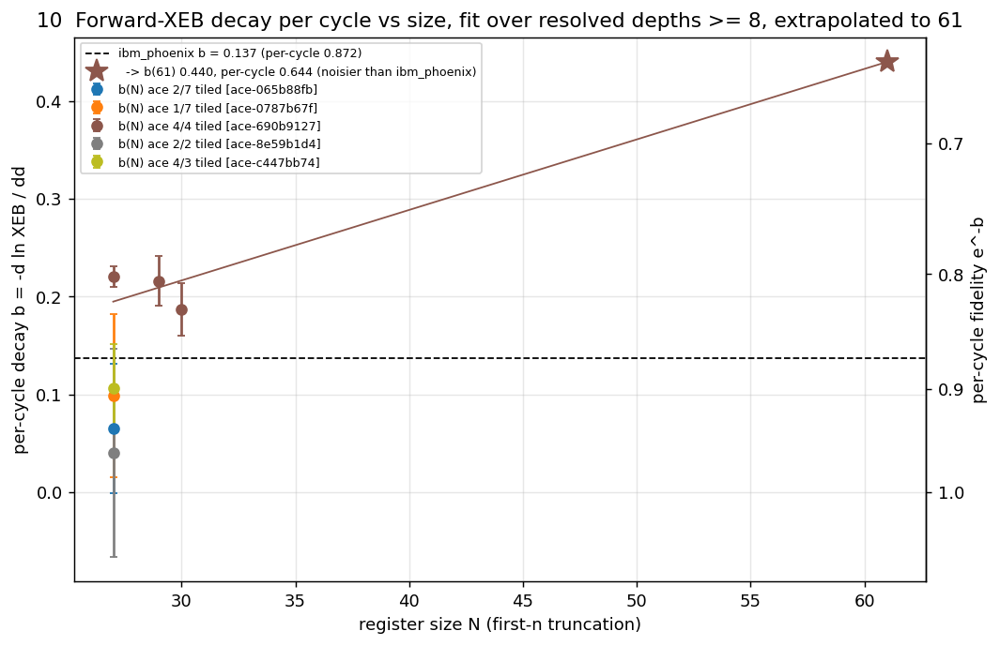


=== 11_fxp.png ===


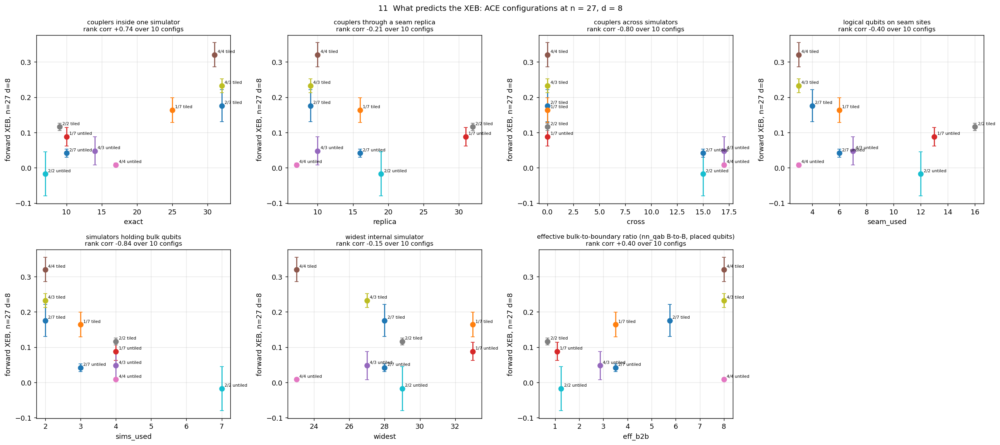


=== 12_hm.png ===


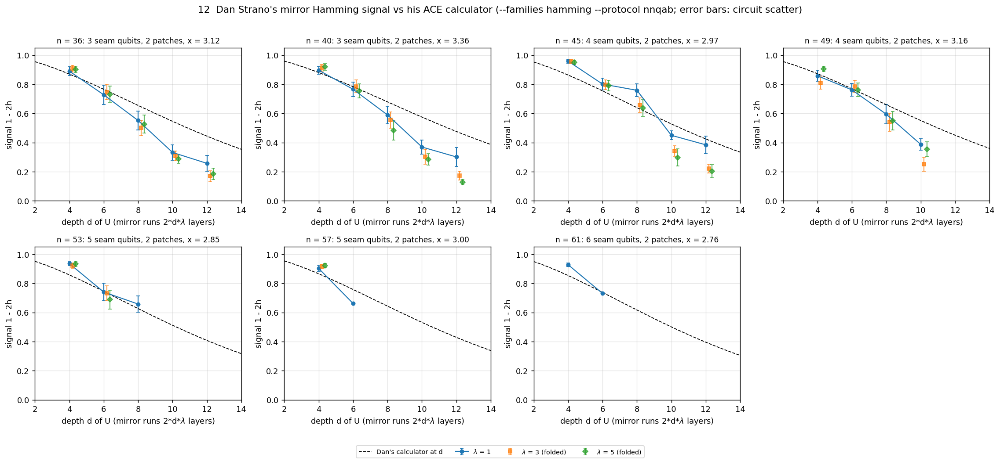


=== 13_hmr.png ===


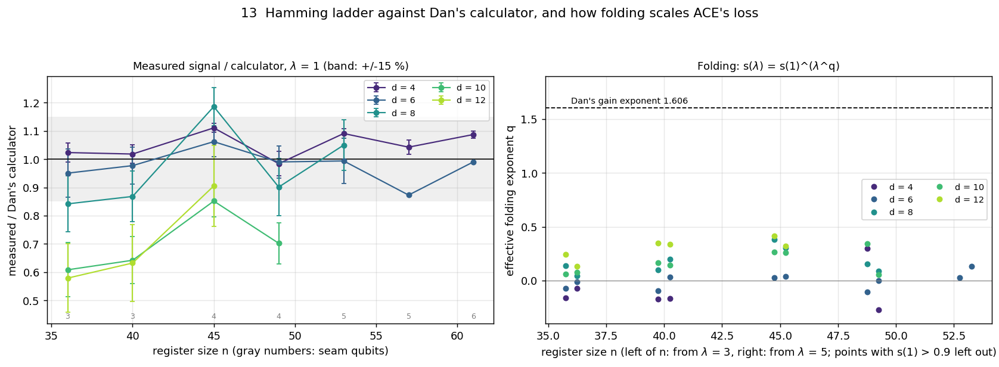

In [14]:
import tarfile
from IPython.display import Image, display

tar_path = Path("../../released/nighthawk/rcs-nighthawk/nighthawk.tar.gz").resolve()
extract_dir = Path("measured_runs")
plots_dir = Path("plots_measured").resolve()
plots_dir.mkdir(exist_ok=True)

if not (extract_dir / "nighthawk").is_dir():
    extract_dir.mkdir(exist_ok=True)
    with tarfile.open(tar_path, "r:gz") as tf:
        if hasattr(tarfile, "data_filter"):      # Python >= 3.12 (and backports): refuse unsafe members
            tf.extractall(extract_dir, filter="data")
        else:
            tf.extractall(extract_dir)

graph_py = Path("nighthawk_graph.py").resolve()
run_cwd = extract_dir / "nighthawk"

run_logged(["python3", str(graph_py), "--table", str(plots_dir / "harvest.csv")], cwd=run_cwd)
run_logged(["python3", str(graph_py), "--save", str(plots_dir)], cwd=run_cwd)

for img_path in sorted(plots_dir.glob("*.png"), key=lambda p: int(p.name.split("_")[0])):
    print(f"\n=== {img_path.name} ===")
    display(Image(filename=str(img_path)))
